<a href="https://colab.research.google.com/github/maxsantana-data2strategy/adventure-works-profitability-analysis-SQL/blob/main/unsupervised-learning-fantasy-sports-clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Unsupervised Learning Practice Project: Fantasy Sports Clustering Analysis**

--------------------------------
## **Context**
-------------------------------

Fantasy sports are online gaming platforms where participants draft and manage virtual teams of real professional sports players. Based on the performance of the players in the real world, players are allotted points in the fantasy sports platform every match. The objective is to create the best possible team with a fixed budget to score maximum fantasy points, and users compete against each other over an entire sports league or season. Some of these fantasy sports require actual financial investments for participation, with the chances of winning monetary rewards as well as free matchday tickets on a periodic basis.

The fantasy sports market has seen tremendous growth over the past few years, with a valuation of \\$18.6 billion in 2019. The football (soccer) segment led in terms of market share in 2019, with over 8 million participants worldwide, and is expected to retain its dominance over the next couple of years. Digitalization is one of the primary factors driving the growth of the fantasy sports market as it allows participants the opportunity to compete on a global level and test their skills. With an increase in smartphone usage and availability of fantasy sports apps, this market is expected to witness a globe surge and reach a \\$48.6 billion valuation by 2027.


----------------------------
## **Objective**
-----------------------------

OnSports is a fantasy sports platform that has fantasy leagues for many different sports and has witnessed an increasing number of participants globally over the past 5 years. For each player, a price is set at the start, and the price keeps changing over time based on the performance of the players in the real world. With the new English Premier League season about to start, they have collected data from the past season and want to analyze it to determine the price of each player for the start of the new season. OnSports have hired you as a data scientist and asked you to conduct a cluster analysis to identify players of different potentials of each player based on previous season performance. This will help them understand the patterns in player performances and fantasy returns and decide the exact price to be set for each player for the upcoming football season.

--------------------------
## **Data Description**
--------------------------

- **Player_Name:** Name of the player.
- **Club:** Club in which the player plays.
- **Position:** Position in which the player plays.
- **Goals_Scored:** Number of goals scored by the player in the previous season.
- **Assists:** Number of passes made by the player leading to goals in the previous season.
- **Total_Points:** Total number of fantasy points scored by the player in the previous season.
- **Minutes:** Number of minutes played by the player in the previous season.
- **Goals_Conceded:** Number of goals conceded by the player in the previous season.
- **Creativity:** A score, computed using a range of stats, that assesses player performance in terms of producing goalscoring opportunities for other players.
- **Influence:** A score, computed using a range of stats, that evaluates a player's impact on a match, taking into account actions that could directly or indirectly affect the match outcome.
- **Threat:** A score, computed using a range of stats, that gauges players who are most likely to score goals.
- **Bonus:** Total bonus points received. The three best performing players in each match receive additional bonus points based on a score computed using a range of stats. 3 points are awarded to the highest scoring player, 2 to the second best, and 1 to the third.
- **Clean_Sheets:** Number of matches without conceding a goal in the previous season.

## **Importing the necessary libraries and overview of the dataset**

**Note**: After running this commands, you’ll be prompted to restart your notebook/runtime. Please go ahead and do that. Once restarted, simply proceed to the next step of your workflow

In [ ]:
#!pip install numpy==1.26.0

**Note:** Please make sure you have installed the sklearn_extra library before running the below cell. If you have not installed the library, please run the below code to install the library:

!pip install scikit-learn-extra

In [ ]:
!pip install scikit-learn-extra

In [ ]:
# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='darkgrid')

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)

# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 200)

# To scale the data using z-score
from sklearn.preprocessing import StandardScaler

# To use PCA
from sklearn.decomposition import PCA

# To compute distances
from scipy.spatial.distance import cdist, pdist

# To perform K-means clustering and compute silhouette scores
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# To import K-Medoids
from sklearn_extra.cluster import KMedoids

# To import DBSCAN and Gaussian Mixture
from sklearn.cluster import DBSCAN
from sklearn.mixture import GaussianMixture

# To perform hierarchical clustering, compute cophenetic correlation, and create dendrograms
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage, cophenet

# To suppress warnings
import warnings
warnings.filterwarnings("ignore")

In [ ]:
# Complete the code to import the data
from google.colab import drive
drive.mount('/content/gdrive')
df = pd.read_csv("/content/gdrive/MyDrive/Applied AI and Data Science/fpl_data Fantasy Sports dataset.csv")

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [ ]:
df.head(10)

,Player_Name,Club,Position,Goals_Scored,Assists,Total_Points,Minutes,Goals_Conceded,Creativity,Influence,Threat,Bonus,Clean_Sheets
0,Alex Runnarsson,Arsenal,Goalkeeper,0,0,1,15,0,0.0,16.6,0,0,0
1,Alexandre Lacazette,Arsenal,Forward,13,3,129,1916,21,307.4,602.4,797,21,7
2,Bernd Leno,Arsenal,Goalkeeper,0,0,131,3131,37,0.0,702.2,2,11,11
3,Bukayo Saka,Arsenal,Midfielder,5,5,114,2554,31,650.6,493.0,984,8,8
4,Calum Chambers,Arsenal,Defender,0,3,36,751,10,169.4,171.8,77,3,2
5,Cedric Soares,Arsenal,Defender,0,1,28,744,11,114.8,110.8,66,3,2
6,Daniel Ceballos,Arsenal,Midfielder,0,4,62,1609,17,422.3,359.8,141,7,6
7,David Luiz,Arsenal,Defender,1,0,41,1396,20,46.7,250.6,144,0,3
8,Edward Nketiah,Arsenal,Forward,2,1,36,411,6,97.3,116.6,211,5,1
9,Emile Smith Rowe,Arsenal,Midfielder,2,5,74,1438,10,385.1,273.2,222,3,9


In [ ]:
# Check the shape of the data
df.shape

(476, 13)

In [ ]:
#Check unique values in players' rows
df["Player_Name"].nunique()

476

In [ ]:
#Check unique values in Club's rows
print("Unique values in Clubs:",df["Club"].nunique())
#Check value counts
print()
print("Value_counts in clubs (Players per Club):", df["Club"].value_counts())

Unique values in Clubs: 17

Value_counts in clubs (Players per Club): Club
Arsenal                     30
Crystal Palace              30
Leeds United                29
Leicester City              29
Newcastle United            29
Tottenham Hotspurs          29
West Ham United             29
Chelsea                     28
Brighton and Hove Albion    28
Manchester United           28
Liverpool                   27
Burnley                     27
Everton                     27
Southampton                 27
Manchester City             27
Aston Villa                 26
Wolverhampton Wanderers     26
Name: count, dtype: int64


In [ ]:
# Let's view a sample of the data
df.sample(n = 10, random_state = 1)

,Player_Name,Club,Position,Goals_Scored,Assists,Total_Points,Minutes,Goals_Conceded,Creativity,Influence,Threat,Bonus,Clean_Sheets
441,Mark Noble,West Ham United,Midfielder,0,0,27,701,15,88.6,80.4,7,0,0
363,Sean Longstaff,Newcastle United,Midfielder,0,1,41,1405,26,182.8,179.2,148,1,2
31,Anwar El Ghazi,Aston Villa,Midfielder,10,0,111,1604,22,426.1,500.4,726,13,5
132,Olivier Giroud,Chelsea,Forward,4,0,47,740,5,112.0,161.4,403,6,4
90,Chris Wood,Burnley,Forward,12,3,138,2741,43,323.2,595.8,1129,16,9
249,Vontae Daley-Campbell,Leicester City,Defender,0,0,0,0,0,0.0,0.0,0,0,0
65,Danny Welbeck,Brighton and Hove Albion,Forward,6,4,89,1541,18,269.7,319.8,595,15,6
445,Ryan Fredericks,West Ham United,Defender,1,1,28,564,9,166.8,155.2,96,0,1
117,Christian Pulisic,Chelsea,Midfielder,4,3,82,1731,21,378.8,361.4,724,3,7
415,Ryan Sessegnon,Tottenham Hotspurs,Defender,0,0,0,0,0,0.0,0.0,0,0,0


In [ ]:
# Checking the column names and datatypes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 476 entries, 0 to 475
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Player_Name     476 non-null    object 
 1   Club            476 non-null    object 
 2   Position        476 non-null    object 
 3   Goals_Scored    476 non-null    int64  
 4   Assists         476 non-null    int64  
 5   Total_Points    476 non-null    int64  
 6   Minutes         476 non-null    int64  
 7   Goals_Conceded  476 non-null    int64  
 8   Creativity      476 non-null    float64
 9   Influence       476 non-null    float64
 10  Threat          476 non-null    int64  
 11  Bonus           476 non-null    int64  
 12  Clean_Sheets    476 non-null    int64  
dtypes: float64(2), int64(8), object(3)
memory usage: 48.5+ KB


In [ ]:
# Copying the data to another variable to avoid any changes to original data
df = df.copy()

In [ ]:
# Check for duplicate values
df.duplicated().sum()

np.int64(0)

In [ ]:
# Check for missing values in the data
df.isna().sum()

,0
Player_Name,0
Club,0
Position,0
Goals_Scored,0
Assists,0
Total_Points,0
Minutes,0
Goals_Conceded,0
Creativity,0
Influence,0


## **Exploratory Data Analysis**

**Let's check the statistical summary of the data**

In [ ]:
df.describe(include= "all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Player_Name,476,476,Willy Boly,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Club,476,17,Arsenal,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Position,476,4,Midfielder,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Goals_Scored,476.0,NaN,NaN,NaN,1.907563,3.455562,0.0,0.0,0.5,2.0,23.0
Assists,476.0,NaN,NaN,NaN,1.752101,2.708563,0.0,0.0,0.0,2.0,14.0
Total_Points,476.0,NaN,NaN,NaN,58.516807,51.293559,0.0,10.0,48.0,94.25,244.0
Minutes,476.0,NaN,NaN,NaN,1336.909664,1073.773995,0.0,268.75,1269.5,2256.25,3420.0
Goals_Conceded,476.0,NaN,NaN,NaN,19.157563,15.946171,0.0,4.0,18.0,31.0,68.0
Creativity,476.0,NaN,NaN,NaN,195.97605,251.478541,0.0,8.3,96.95,296.95,1414.9
Influence,476.0,NaN,NaN,NaN,294.617647,267.779681,0.0,46.5,233.1,499.5,1318.2


### **Summary of Descriptive Statistics**

* **Top Performers & Value Drivers:** The maximum fantasy points scored by a player is **244**, with maximum goals scored at **23** and assists at **14**. These high-performing elite players (top 25% starting around **94+ points**) will command the highest premium pricing tiers.
* **The 'Squad Player' Baseline:** More than 50% of the players scored **48 points or fewer** and played under **1,270 minutes** (roughly 14 full matches). Many players have 0 minutes played. This indicates a large cluster of budget/enabler players who should be priced at the absolute baseline.
* **Match Involvement vs. Returns:** There is significant variation in player involvement (minutes range from **0 to 3,420**). Ensuring price points reflect active match-time guarantees will prevent fantasy managers from overpaying for inactive squad members.
* **Defensive Clean Sheets:** Clean sheets range up to **19**, representing elite defensive and goalkeeper selections that provide a highly stable alternative source of points compared to volatile attackers.

### **Univariate Analysis**

In [ ]:
cyberpunk_palette = ["#00f0ff", "#ff0055", "#ccff00", "#7000ff"]

**`Goals_Scored`**

In [ ]:
def cyberpunk_histogram_boxplot(data, feature, player_name_col='Player_Name', figsize=(12, 7), kde=True, bins=20, show_outlier_labels=True):
    # Apply cyberpunk style settings
    plt.style.use('dark_background')
    fig = plt.figure(figsize=figsize, facecolor='#0a0a12')

    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,
        sharex=True,
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
        facecolor='#0a0a12'
    )

    # Set axes facecolors
    ax_box2.set_facecolor('#0a0a12')
    ax_hist2.set_facecolor('#0a0a12')

    # Boxplot in Neon Pink
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True,
        color="#ff0055", medianprops={'color': '#ffffff', 'linewidth': 2},
        meanprops={'markerfacecolor': '#ccff00', 'markeredgecolor': '#ccff00'},
        flierprops={'markerfacecolor': '#00f0ff', 'markeredgecolor': '#00f0ff', 'marker': 'o'}
    )

    # Label top three outliers if enabled
    if show_outlier_labels:
        top_3 = data.nlargest(3, feature).copy()
        y_box_center = 0  # Default y-coordinate for points in a single 1D boxplot

        # Adjust positions if there are ties to prevent overlapping labels
        offsets_y = [-0.15, -0.35, -0.15]

        # Calculate an automatic horizontal shift based on the range of the feature
        feature_range = data[feature].max() - data[feature].min()
        shift_amount = feature_range * 0.045 if feature_range > 0 else 0.5

        # We create custom X coordinates for labels if they share the exact same value
        xs = top_3[feature].values.astype(float)
        if len(xs) >= 3:
            # Check for three-way tie or close pairs
            if xs[0] == xs[1] == xs[2]:
                xs[0] = xs[0] - shift_amount
                xs[2] = xs[2] + shift_amount
            elif xs[0] == xs[1]:
                xs[0] = xs[0] - shift_amount/2
                xs[1] = xs[1] + shift_amount/2
            elif xs[1] == xs[2]:
                xs[1] = xs[1] - shift_amount/2
                xs[2] = xs[2] + shift_amount/2

        for i, (idx, row) in enumerate(top_3.iterrows()):
            ax_box2.text(
                xs[i],
                y_box_center + offsets_y[i],
                row[player_name_col],
                color='#00f0ff',
                ha='center',
                va='bottom',
                fontsize=9,
                fontweight='bold',
                bbox=dict(boxstyle="round,pad=0.3", fc="#0a0a12", ec="#00f0ff", lw=1, alpha=0.8)
            )

    # Histogram in Neon Cyan / Blue with custom-colored KDE line
    if bins:
        sns.histplot(
            data=data, x=feature, kde=True, ax=ax_hist2, bins=bins, color="#00f0ff", alpha=0.7,
            line_kws={'color': '#ff0055', 'linewidth': 3}
        )
    else:
        sns.histplot(
            data=data, x=feature, kde=True, ax=ax_hist2, color="#00f0ff", alpha=0.7,
            line_kws={'color': '#ff0055', 'linewidth': 3}
        )

    # Mean and Median line indicators
    ax_hist2.axvline(data[feature].mean(), color='#ccff00', linestyle='--', linewidth=2, label='Mean')
    ax_hist2.axvline(data[feature].median(), color='#ffffff', linestyle='-', linewidth=2, label='Median')

    # Clean gridlines and labels
    ax_hist2.grid(True, color='#1f2335', linestyle=':', alpha=0.6)
    ax_box2.grid(False)

    ax_hist2.set_xlabel(feature, color='#00f0ff', fontsize=12)
    ax_hist2.set_ylabel('Count', color='#00f0ff', fontsize=12)

    plt.tight_layout()
    plt.show()
    # Revert to standard style
    plt.style.use('default')
    sns.set_theme(style='darkgrid')

<Figure size 1200x700 with 0 Axes>

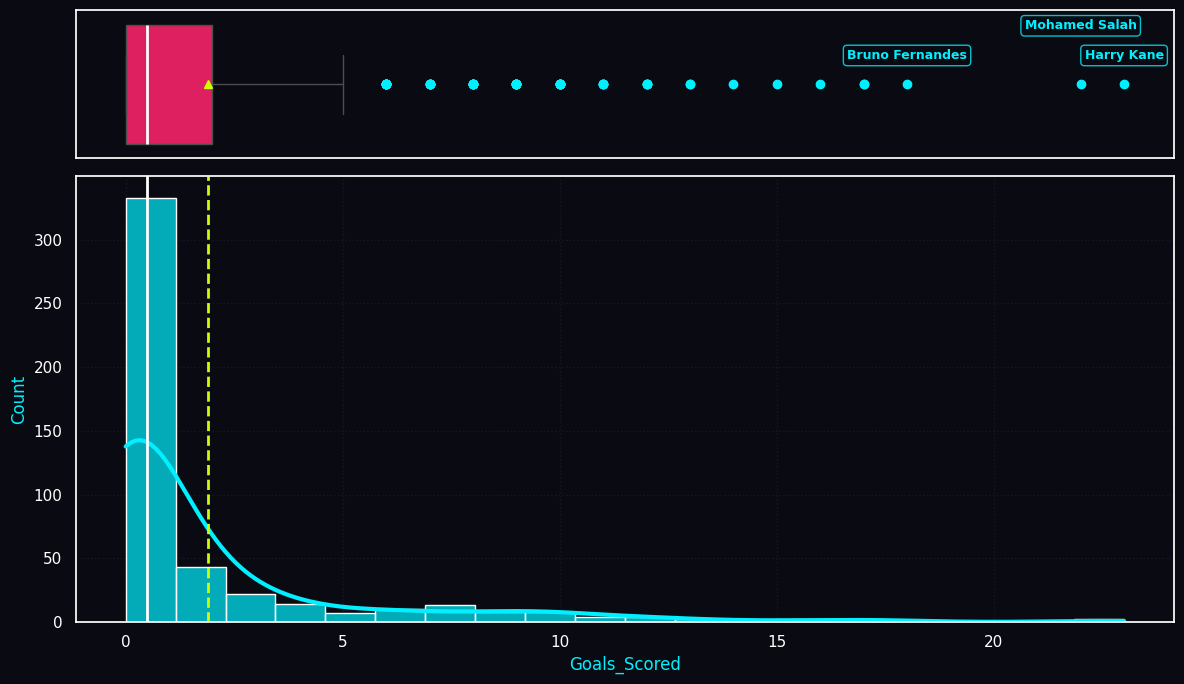

In [ ]:
cyberpunk_histogram_boxplot(df, 'Goals_Scored')

In [ ]:
# Find the top 3 players with the most goals
top_3_goalscorers = df.nlargest(3, 'Goals_Scored')
display(top_3_goalscorers[['Player_Name', "Position","Club",'Goals_Scored']].sort_values('Goals_Scored', ascending=False))

,Player_Name,Position,Club,Goals_Scored
403,Harry Kane,Forward,Tottenham Hotspurs,23
269,Mohamed Salah,Midfielder,Liverpool,22
315,Bruno Fernandes,Midfielder,Manchester United,18


**`Assists`**

<Figure size 1200x700 with 0 Axes>

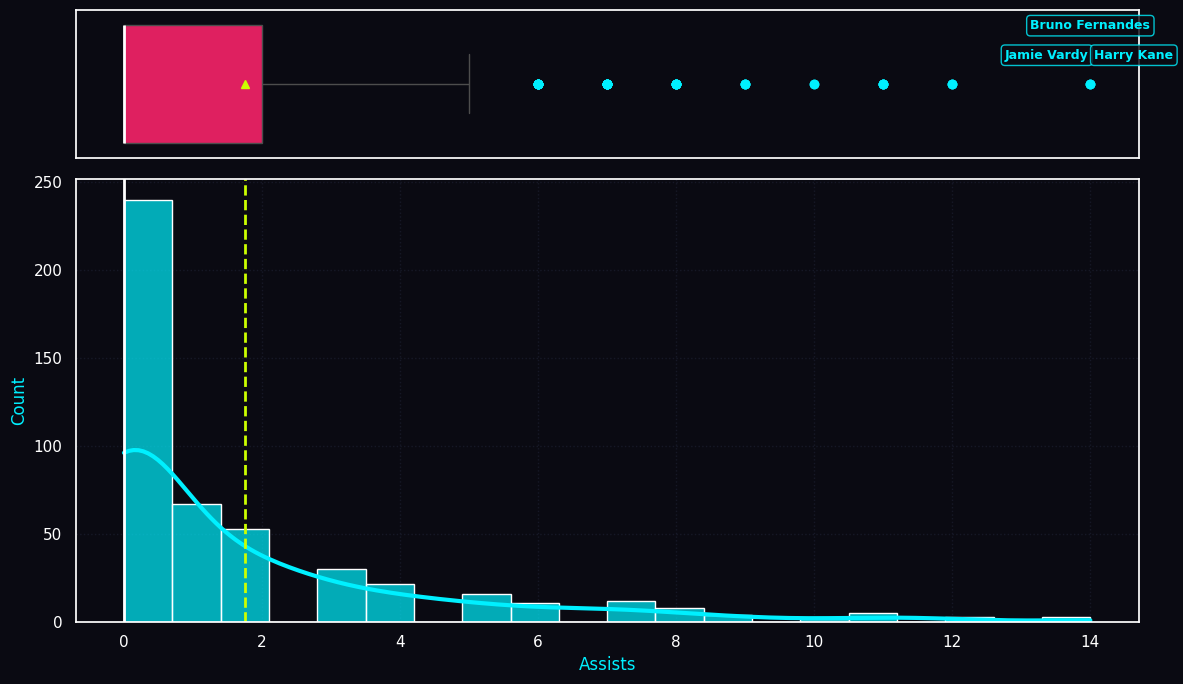

In [ ]:
# Histogram_boxplot for 'Assists' to check the updated tie-breaker labeling logic
cyberpunk_histogram_boxplot(df, 'Assists')

In [ ]:
# Find the top 3 players with the most assists
top_5_assists = df.nlargest(5, 'Assists')
display(top_5_assists[['Player_Name',"Position", "Club",'Assists']])

,Player_Name,Position,Club,Assists
238,Jamie Vardy,Forward,Leicester City,14
315,Bruno Fernandes,Midfielder,Manchester United,14
403,Harry Kane,Forward,Tottenham Hotspurs,14
39,Jack Grealish,Midfielder,Aston Villa,12
136,Timo Werner,Forward,Chelsea,12


<Figure size 1200x700 with 0 Axes>

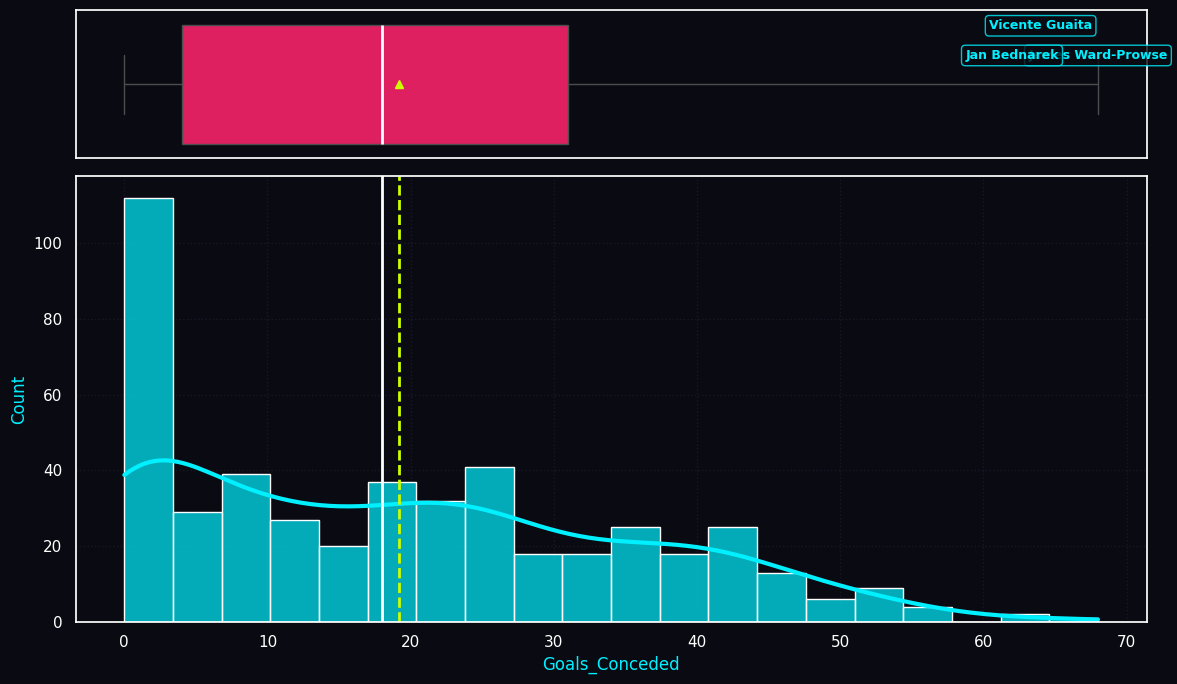

In [ ]:
# Plot the histogram and the boxplot for 'Goals_Conceded'
cyberpunk_histogram_boxplot(df, 'Goals_Conceded')

In [ ]:
top_3_goals_conceded = df.nlargest(3, 'Goals_Conceded')
display(top_3_goals_conceded[['Player_Name', "Position","Club",'Goals_Conceded']])

,Player_Name,Position,Club,Goals_Conceded
374,James Ward-Prowse,Midfielder,Southampton,68
167,Vicente Guaita,Goalkeeper,Crystal Palace,64
375,Jan Bednarek,Defender,Southampton,62


<Figure size 1200x700 with 0 Axes>

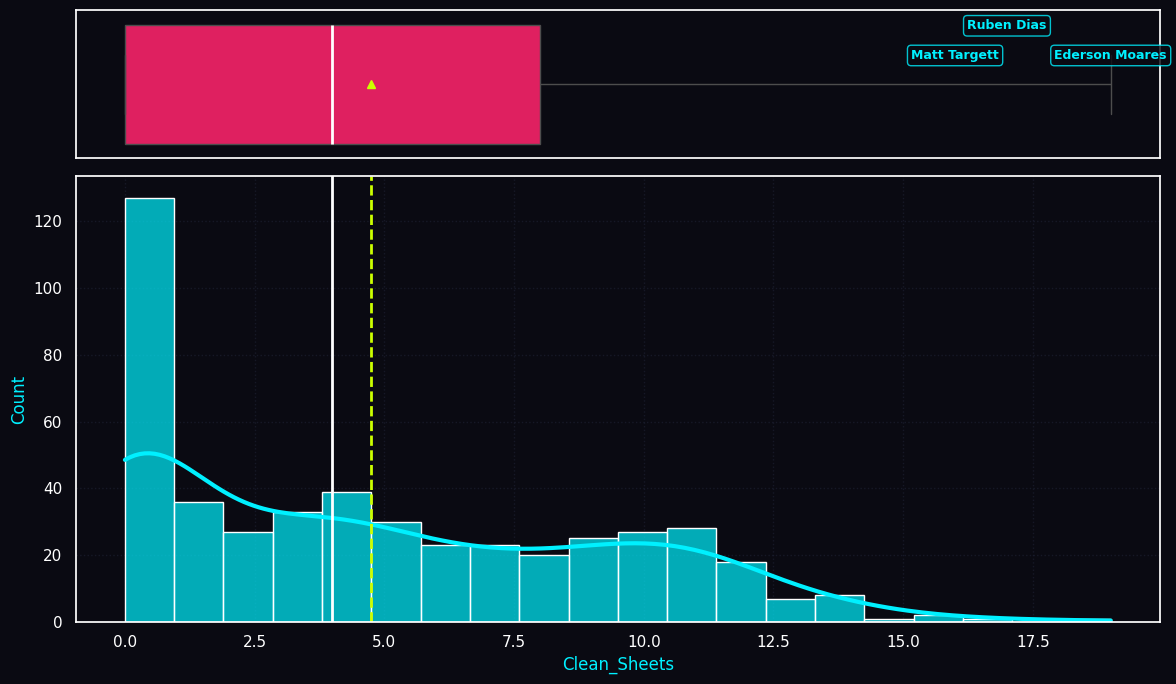

In [ ]:
# Plot the histogram and the boxplot for 'Clean_Sheets'
cyberpunk_histogram_boxplot(df, "Clean_Sheets")

In [ ]:
top_3_clean_sheets = df.nlargest(3, 'Clean_Sheets')
display(top_3_clean_sheets[['Player_Name', "Position","Club",'Clean_Sheets']])

,Player_Name,Position,Club,Clean_Sheets
284,Ederson Moares,Goalkeeper,Manchester City,19
303,Ruben Dias,Defender,Manchester City,17
48,Matt Targett,Defender,Aston Villa,16


<Figure size 1200x700 with 0 Axes>

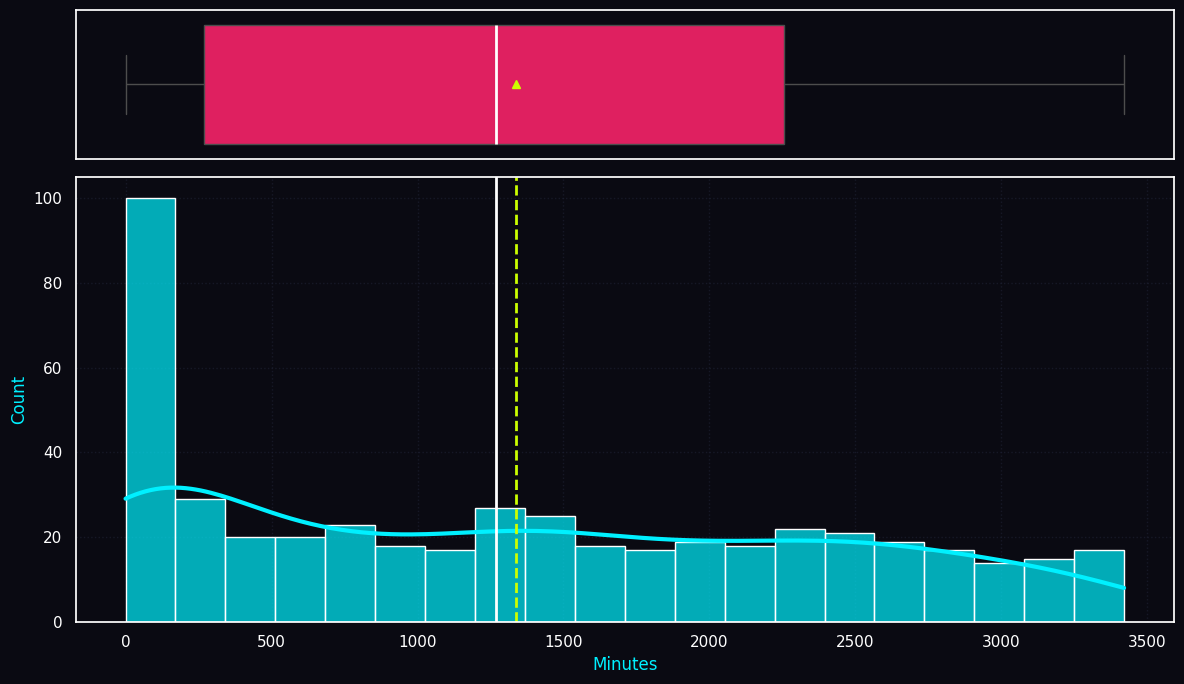

In [ ]:
# Plot the histogram and the boxplot for 'Minutes'
cyberpunk_histogram_boxplot(df, "Minutes", show_outlier_labels=False)

In [ ]:
top_10_most_minutes = df.nlargest(10, 'Minutes')
display(top_10_most_minutes[['Player_Name', "Position","Club",'Minutes']])

,Player_Name,Position,Club,Minutes
36,Emiliano Martinez,Goalkeeper,Aston Villa,3420
240,Kasper Schmeichel,Goalkeeper,Leicester City,3420
374,James Ward-Prowse,Midfielder,Southampton,3420
406,Hugo Lloris,Goalkeeper,Tottenham Hotspurs,3420
414,Pierre-Emile Hojbjerg,Midfielder,Tottenham Hotspurs,3420
448,Tomas Soucek,Midfielder,West Ham United,3420
86,Ashley Westwood,Midfielder,Burnley,3410
223,Stuart Dallas,Defender,Leeds United,3410
48,Matt Targett,Defender,Aston Villa,3404
213,Luke Ayling,Defender,Leeds United,3399


<Figure size 1200x700 with 0 Axes>

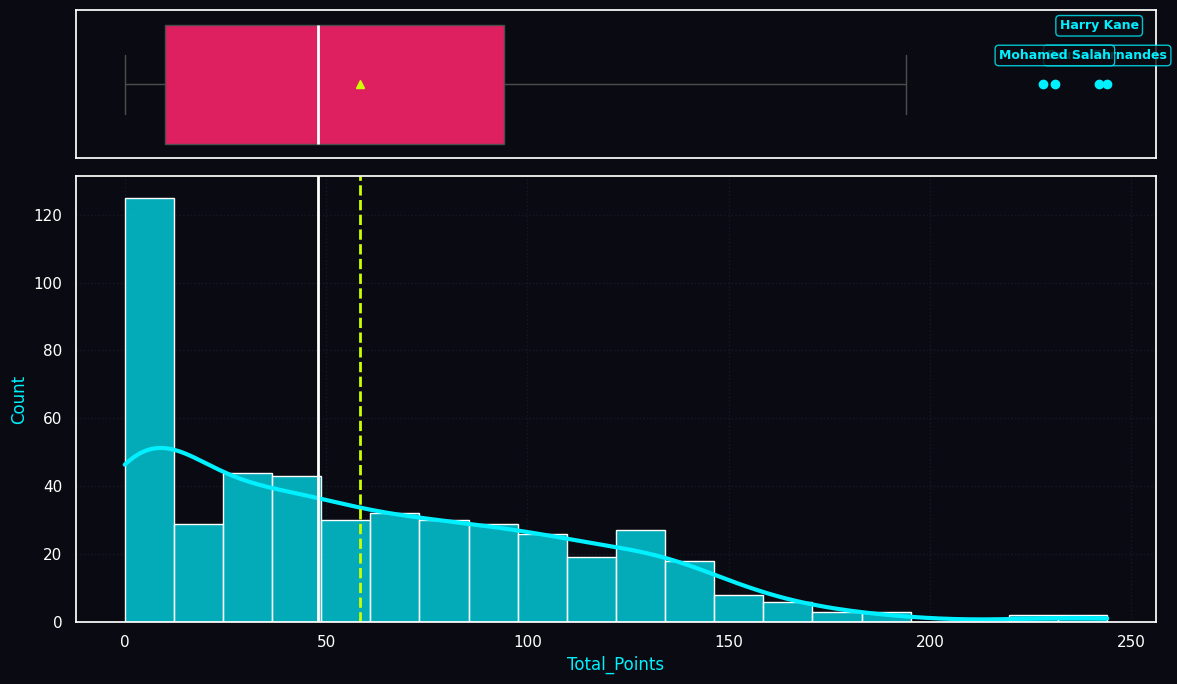

In [ ]:
# Plot the histogram and the boxplot for 'Total_Points'
cyberpunk_histogram_boxplot(df, 'Total_Points')


In [ ]:
top_3_total_points = df.nlargest(3, 'Total_Points')
display(top_3_total_points[['Player_Name', "Position", "Club",'Total_Points']])

,Player_Name,Position,Club,Total_Points
315,Bruno Fernandes,Midfielder,Manchester United,244
403,Harry Kane,Forward,Tottenham Hotspurs,242
269,Mohamed Salah,Midfielder,Liverpool,231


<Figure size 1200x700 with 0 Axes>

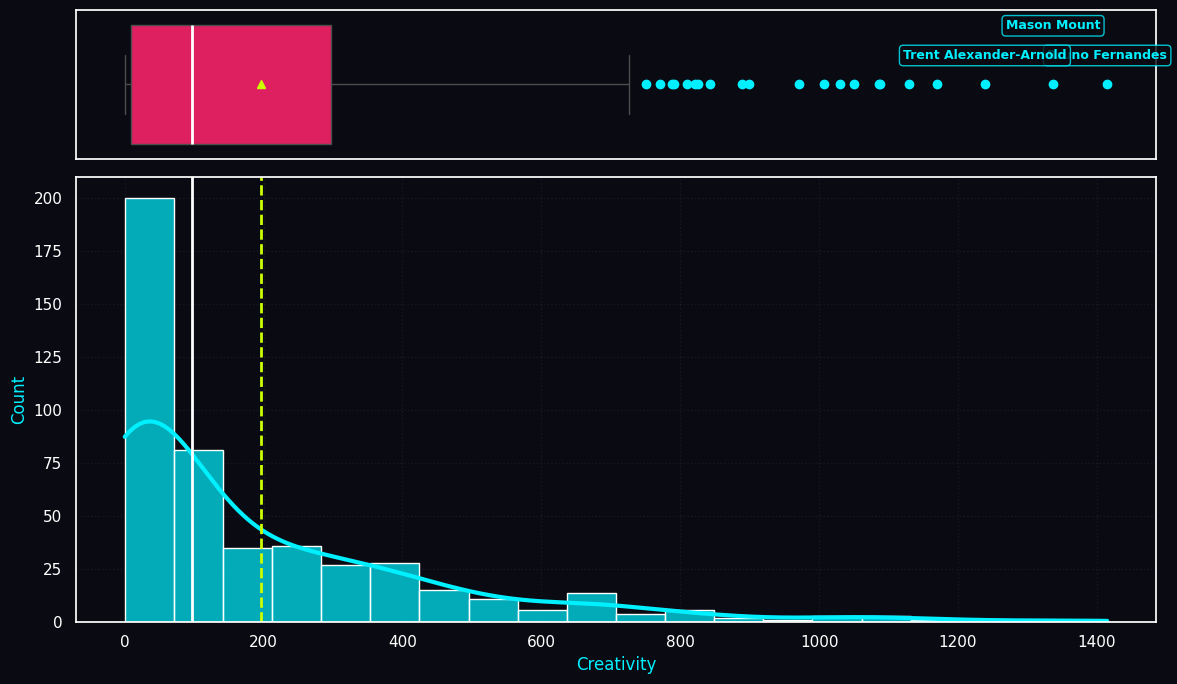

In [ ]:
# Plot the histogram and the boxplot for 'Creativity'
cyberpunk_histogram_boxplot(df, 'Creativity')

In [ ]:
top_3_creativity = df.nlargest(3, 'Creativity')
display(top_3_creativity[['Player_Name', "Position","Club",'Creativity']])

,Player_Name,Position,Club,Creativity
315,Bruno Fernandes,Midfielder,Manchester United,1414.9
129,Mason Mount,Midfielder,Chelsea,1336.9
278,Trent Alexander-Arnold,Defender,Liverpool,1238.8


<Figure size 1200x700 with 0 Axes>

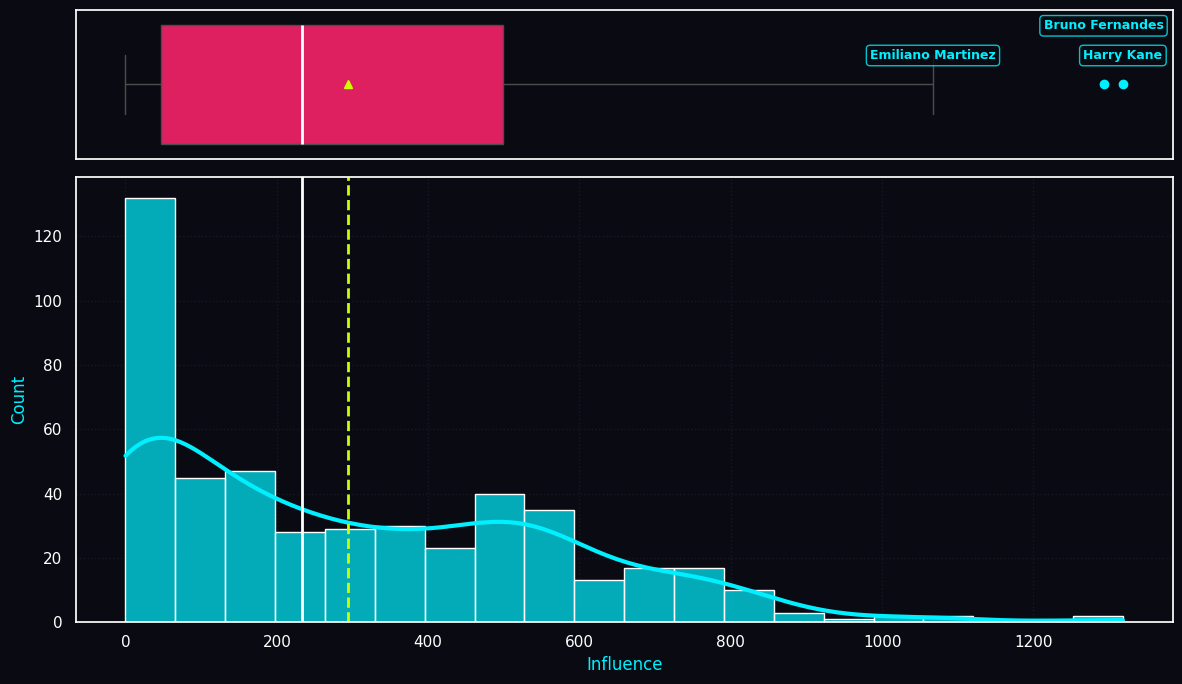

In [ ]:
# Plot the histogram and the boxplot for 'Influence'
cyberpunk_histogram_boxplot(df, 'Influence')

In [ ]:
top_3_influence = df.nlargest(3, 'Influence')
display(top_3_influence[['Player_Name', "Position","Club",'Influence']])

,Player_Name,Position,Club,Influence
403,Harry Kane,Forward,Tottenham Hotspurs,1318.2
315,Bruno Fernandes,Midfielder,Manchester United,1292.6
36,Emiliano Martinez,Goalkeeper,Aston Villa,1067.2


<Figure size 1200x700 with 0 Axes>

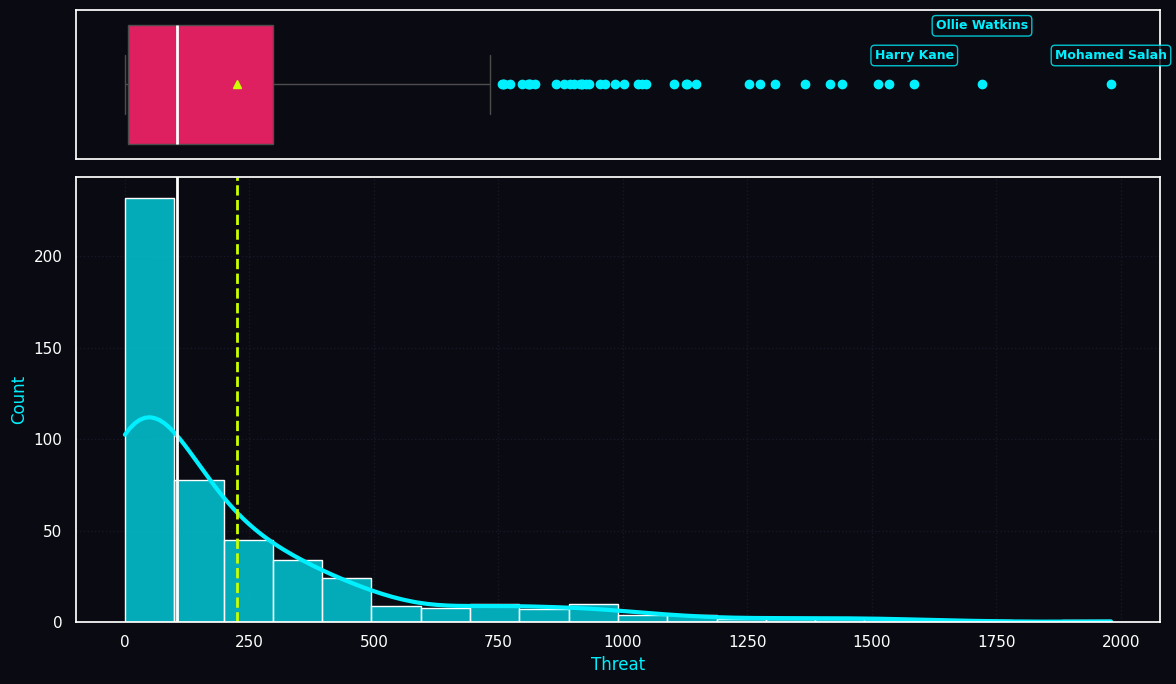

In [ ]:
# Plot the histogram and the boxplot for 'Threat'
cyberpunk_histogram_boxplot(df, 'Threat')

In [ ]:
top_3_threat = df.nlargest(3, 'Threat')
display(top_3_threat[['Player_Name', "Position","Club",'Threat']])

,Player_Name,Position,Club,Threat
269,Mohamed Salah,Midfielder,Liverpool,1980
51,Ollie Watkins,Forward,Aston Villa,1721
403,Harry Kane,Forward,Tottenham Hotspurs,1585


<Figure size 1200x700 with 0 Axes>

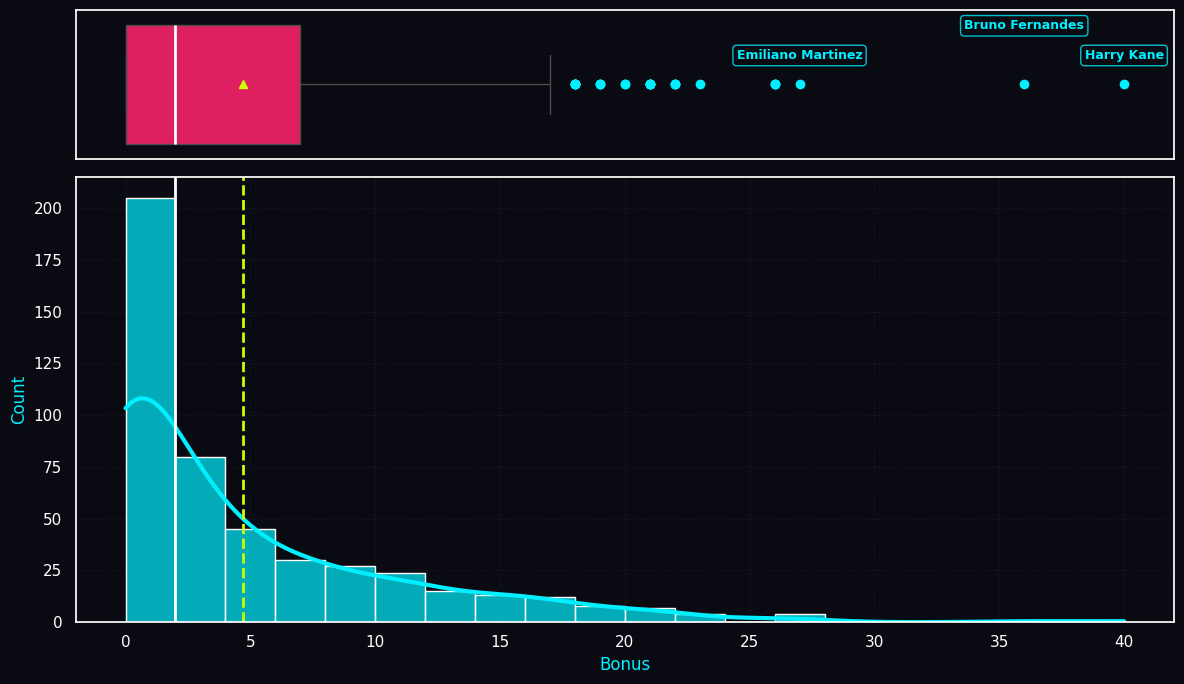

In [ ]:
# Plot the histogram and the boxplot for 'Bonus'
cyberpunk_histogram_boxplot(df, 'Bonus')

In [ ]:
top_3_bonus = df.nlargest(3, 'Bonus')
display(top_3_bonus[['Player_Name', "Position","Club",'Bonus']])

,Player_Name,Position,Club,Bonus
403,Harry Kane,Forward,Tottenham Hotspurs,40
315,Bruno Fernandes,Midfielder,Manchester United,36
36,Emiliano Martinez,Goalkeeper,Aston Villa,27


### **Observations and Insights for all the plots**

Based on the univariate distributions and top player rankings, we can draw several critical insights about the player pool:

1. **Severe Right Skewness in Attacking & Creative Stats (`Goals_Scored`, `Assists`, `Creativity`, `Threat`, `Bonus`):**
   * The vast majority of players contribute very little to attacking statistics, with the distribution peaks sitting near $0$. This indicates that consistent attacking output is a premium, elite trait limited to a small group of high-priced outliers.
   * **Goals & Threat:** **Mohamed Salah** (Liverpool, Midfielder) and **Harry Kane** (Tottenham, Forward) lead both goalscoring and overall threat metrics. This highlights that midfielders with high goalscorer potential and pure elite forwards are the primary targets for premium pricing.
   * **Creativity & Assists:** **Bruno Fernandes** (Manchester United) dominates creativity and assists alongside **Harry Kane** and **Jamie Vardy**. This suggests a high-pricing benchmark for attacking midfielders who double as focal points for chance creation.

2. **Wide Spread and High Baseline of Active Players (`Minutes`):**
   * The minutes played distribution shows a large spike at $0$, representing injured or non-selected squad players, followed by a relatively uniform distribution up to $3,400+$ minutes.
   * Goalkeepers like **Emiliano Martínez** (Aston Villa) and reliable box-to-box midfielders like **James Ward-Prowse** (Southampton) are highly durable, racking up maximum minutes. Durable players represent stable budget/mid-tier options.

3. **Defensive Stability (`Clean_Sheets` & `Goals_Conceded`):**
   * Clean sheets sit as a reliable source of points for defensive units from top-performing clubs, led by **Ederson Moares** and **Rúben Dias** from Manchester City.
   * Conversely, defensive assets from lower-table clubs (such as **Vicente Guaita** or **Jan Bednarek**) suffer high goals conceded rates, lowering their fantasy value despite high minutes played.

4. **Overall Value Drivers (`Total_Points`):**
   * **Bruno Fernandes**, **Harry Kane**, and **Mohamed Salah** represent the absolute elite echelon ($220+$ total points).
   * The massive bulk of the league clusters below $50$ points, indicating OnSports should implement a sharp exponential price scaling strategy rather than a linear one.

In [ ]:
def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot con temática cyberpunk y porcentajes o conteos en la parte superior.

    data: dataframe
    feature: columna del dataframe
    perc: si se muestran porcentajes en lugar de conteos (por defecto False)
    n: muestra los primeros n niveles de categorías
    """
    # Aplicar temporalmente estilo de fondo oscuro
    plt.style.use('dark_background')

    total = len(data[feature])
    count = data[feature].nunique()

    # Determinar el tamaño de la figura según las categorías (corregido 'null' a 'None')
    figsize_val = (n + 2, 6) if n is not None else (count + 2, 6)

    fig, ax = plt.subplots(figsize=figsize_val, facecolor='#0a0a12')
    ax.set_facecolor('#0a0a12')

    # Ordenar y seleccionar categorías
    order = data[feature].value_counts().index[:n]
    # Graficar con paleta cyberpunk 'cool' (gradiente cian a rosa neón)
    sns.countplot(
        data=data,
        x=feature,
        palette="cool",
        order=order,
        ax=ax
    )

    # Rotación y estilo de etiquetas del eje X
    plt.xticks(rotation=90, fontsize=11, color='#00f0ff', fontweight='bold')
    plt.yticks(fontsize=10, color='#00f0ff')

    # Personalizar etiquetas de ejes
    ax.set_xlabel(feature, color='#00f0ff', fontsize=12, fontweight='bold')
    ax.set_ylabel('Count', color='#00f0ff', fontsize=12, fontweight='bold')

    # Agregar rejilla sutil de fondo
    ax.grid(True, color='#1f2335', linestyle=':', alpha=0.5)
    ax.set_axisbelow(True)

    # Anotar los valores sobre las barras con estilo neón
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            if perc:
                label = "{:.1f}%".format(100 * height / total)
            else:
                label = int(height)

            x = p.get_x() + p.get_width() / 2
            y = height

            ax.annotate(
                label,
                (x, y),
                ha='center',
                va='center',
                size=10,
                xytext=(0, 8),
                textcoords='offset points',
                color='#ffffff',
                fontweight='bold',
                bbox=dict(boxstyle="round,pad=0.2", fc="#0a0a12", ec="#ff0055", lw=1, alpha=0.9)
            )

    plt.tight_layout()
    plt.show()

    # Reestablecer el tema por defecto de seaborn
    plt.style.use('default')
    sns.set_theme(style='darkgrid')

**`Club`**

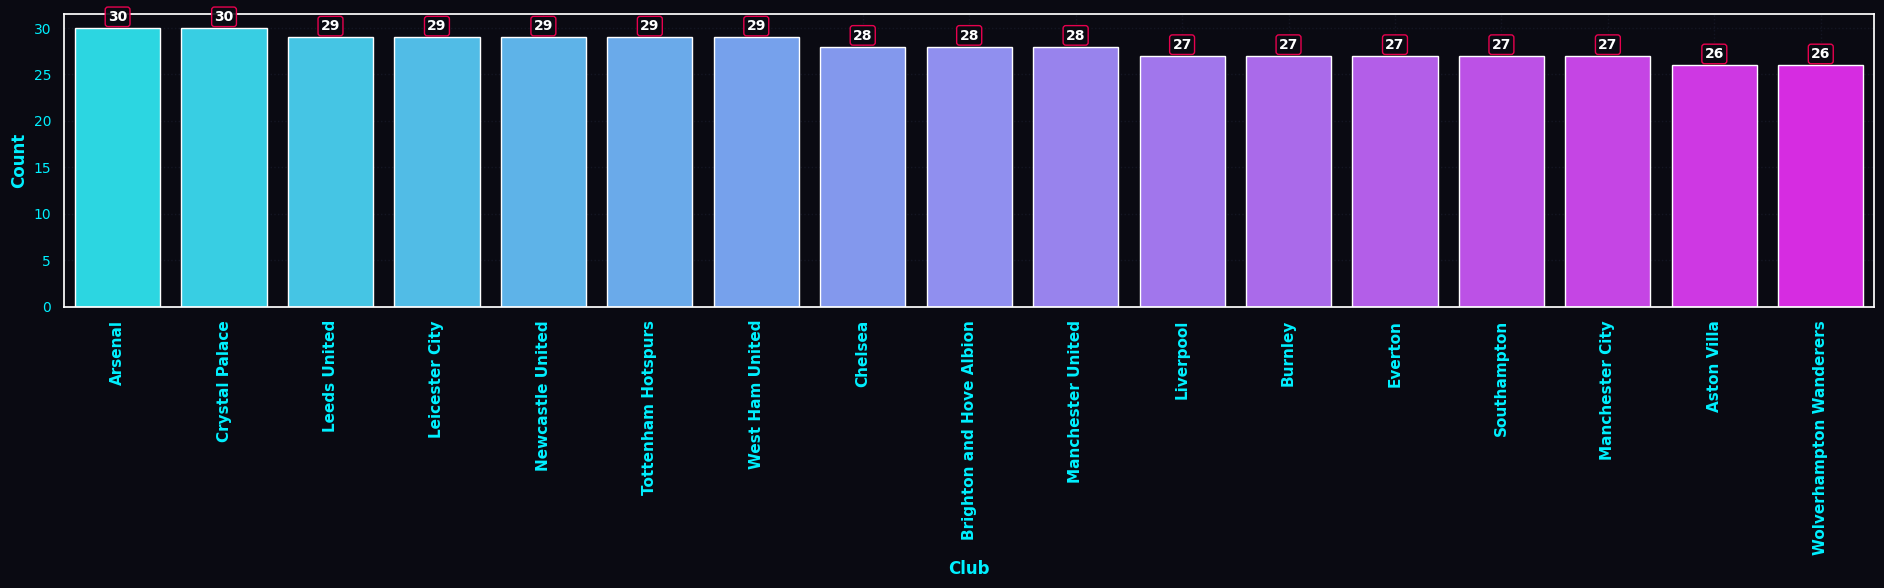

In [ ]:
# Execute the custom labeled_barplot with our corrected cyberpunk design
labeled_barplot(df, 'Club')

**`Position`**

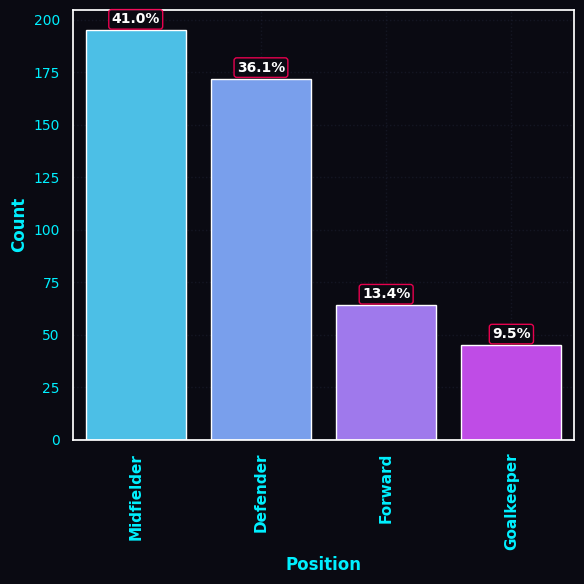

In [ ]:
# Execute the custom labeled_barplot for 'Position' with our corrected cyberpunk design
labeled_barplot(df, 'Position', perc= True)

**Observations and Insights:**

- The dataset covers 17 Premier League clubs, with squad sizes ranging consistently between 26 and 30 players per team (led by Arsenal and Crystal Palace with 30 players each, and Aston Villa and Wolverhampton with 26).

- This relatively balanced squad representation across clubs ensures that our upcoming unsupervised clustering models will not suffer from severe sample size biases driven by over-represented teams.

Positional Breakdown (Position):

- Players are categorized into 4 distinct tactical positions: Midfielders, Defenders, Forwards, and Goalkeepers.

- Midfielders make up the largest share of the player pool (195 players, roughly 41%), reflecting the tactical versatility of the position—ranging from defensive workhorses to elite goalscoring wingers and playmakers (such as Bruno Fernandes and Mohamed Salah).

- The balanced distribution across positions allows the clustering algorithm to effectively segment players based on role-specific performance metrics rather than arbitrary positional volume.

### **Bivariate Analysis**

**We are done with univariate analysis. Let's explore the data a bit more with bivariate analysis.**

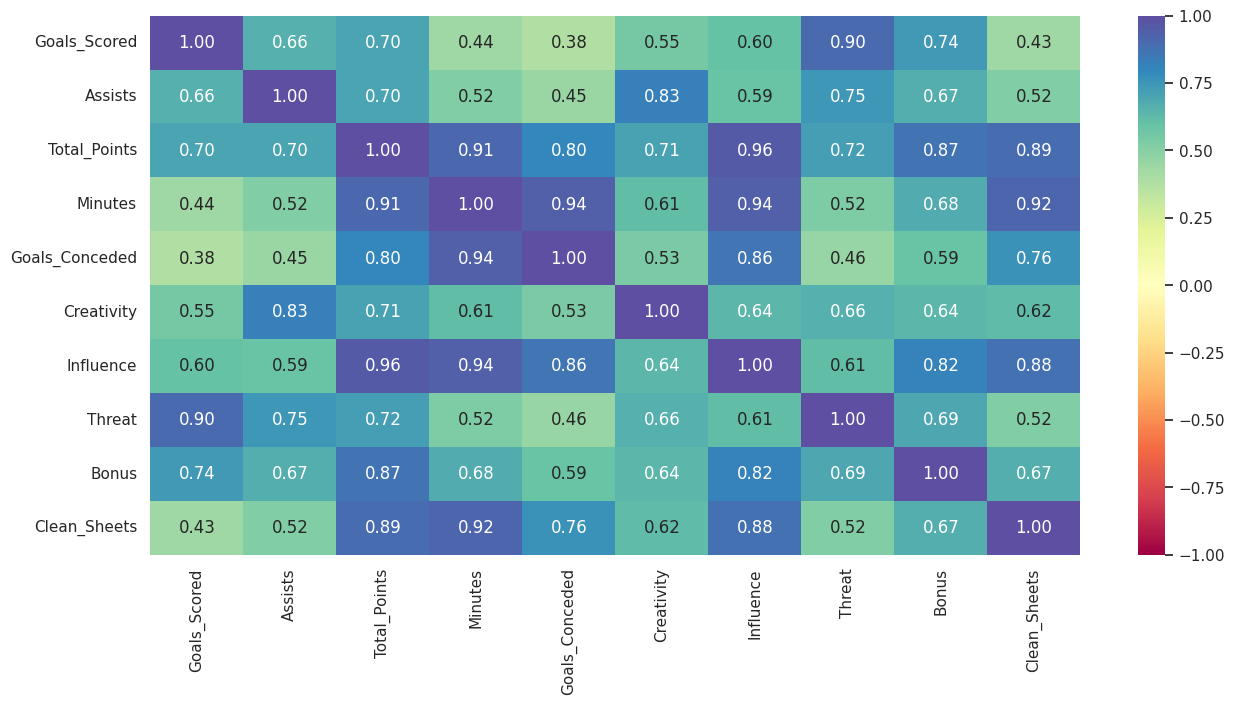

In [ ]:
# Correlation check
cols_list = df.select_dtypes(include = np.number).columns.tolist()

plt.figure(figsize = (15, 7))

sns.heatmap(
    df[cols_list].corr(numeric_only = True), annot = True, vmin = -1, vmax = 1, fmt = ".2f", cmap = "Spectral"
)

plt.show()

**Observations and Insights:**

- Primary Drivers of Fantasy Points (Total_Points):

  - Influence (0.96), Minutes (0.91), Clean_Sheets (0.89), and Bonus (0.87) exhibit exceptionally strong positive correlations with total fantasy points. This indicates that a player's durability (playing time) and overall match impact are fundamental drivers of fantasy success, often matching or exceeding raw goalscoring volume.

  - Direct goal contributions (Goals_Scored at 0.70) and playmaking (Assists at 0.70) maintain strong, steady linear relationships with points, but are heavily amplified by bonus point systems.

- Validation of Fantasy Premier League Performance Metrics:
  - Goals_Scored correlates very strongly with Threat (0.90), proving that the platform's proprietary Threat index successfully captures underlying goal-scoring probability.

  - Assists shows a high correlation with Creativity (0.83), confirming that creative chance creation directly maps to assist production on the pitch.

- High Multicollinearity & Structural Redundancy:

    - Several variables exhibit severe collinearity due to cumulative match exposure—notably Minutes vs. Goals_Conceded (0.94), Minutes vs. Influence (0.94), and Clean_Sheets vs. Minutes (0.92).

    - Because cumulative volume statistics scale together across a full 38-game season, this high inter-correlation validates the necessity of applying Principal Component Analysis (PCA) to reduce dimensionality before running unsupervised clustering models.

**Let's check players from which team have scored the most fantasy points on average.**

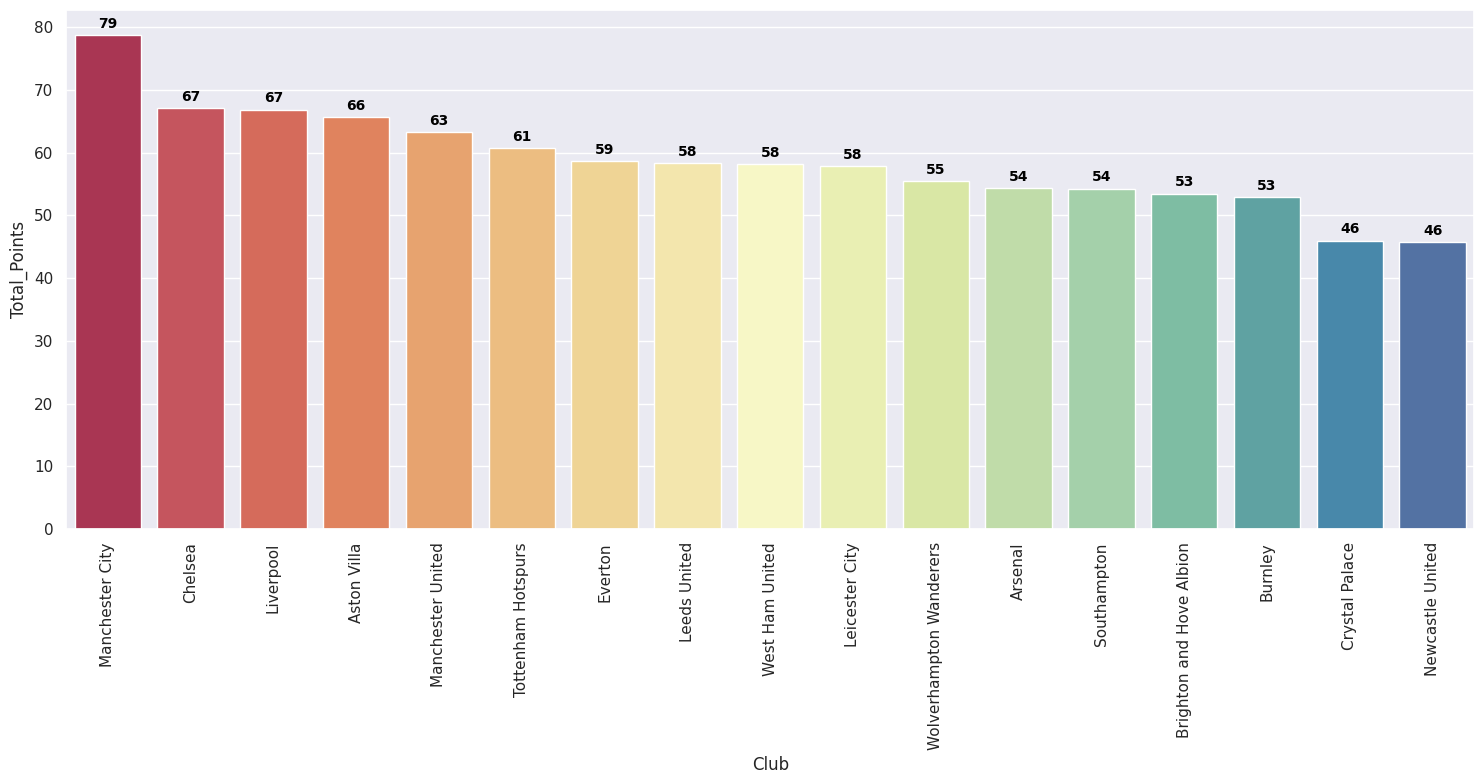

In [ ]:
club_order = df.groupby('Club')['Total_Points'].mean().sort_values(ascending=False).index

plt.figure(figsize=(15, 8))
ax = sns.barplot(
    data=df,
    x="Club",
    y="Total_Points",
    errorbar=('ci', False),
    order=club_order,
    palette="Spectral"
)
plt.xticks(rotation=90)

# Add value labels with explicit color so they are visible
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f"{height:.0f}",
            (p.get_x() + p.get_width() / 2., height),
            ha='center',
            va='bottom',
            xytext=(0, 3),
            textcoords='offset points',
            fontsize=10,
            fontweight='bold',
            color='black'  # <-- Added explicit white color
        )

plt.tight_layout()
plt.show()

**We know that players in different positions have specific roles to play in a team. Let's check players in which positions tend to score more fantasy points on average.**

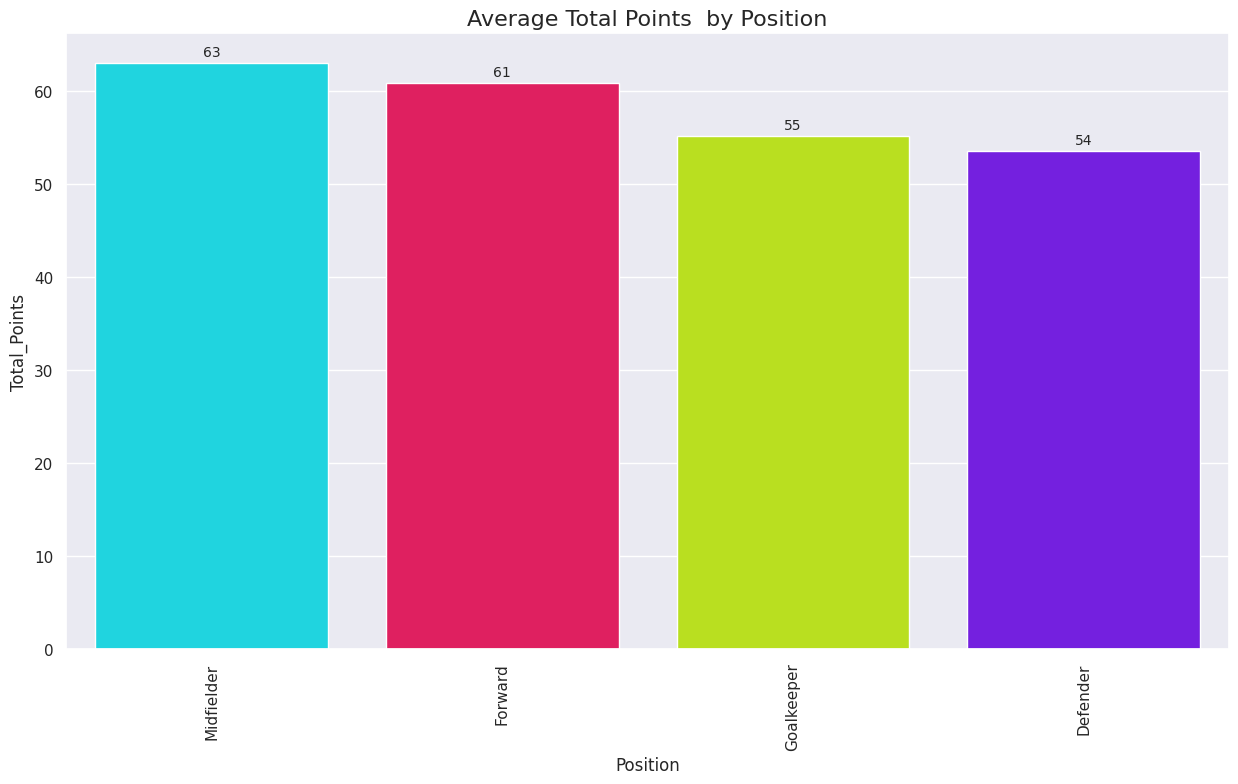

In [ ]:
# Complete the code with the right variables
plt.figure(figsize=(15, 8))
ax = sns.barplot(
    data=df,
    x="Position",
    y="Total_Points",
    errorbar=('ci', False),
    palette=cyberpunk_palette,
    order = df.groupby('Position')['Total_Points'].mean().sort_values(ascending=False).index
)
plt.xticks(rotation=90)
#Add percentage per bar column
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(f"{height:.0f}",
                (bar.get_x() + bar.get_width() / 2, height),
                ha='center', va='center',
                size=10, xytext=(0,
                                 8),
                textcoords='offset points')
#Add title
plt.title("Average Total Points  by Position", loc='center', fontsize=16)
plt.show()

**To effectively utilize their squad depth, managers often rotate the squad to keep key players in shape for tougher games. Let's check the total number of minutes played, on average, across different positions.**

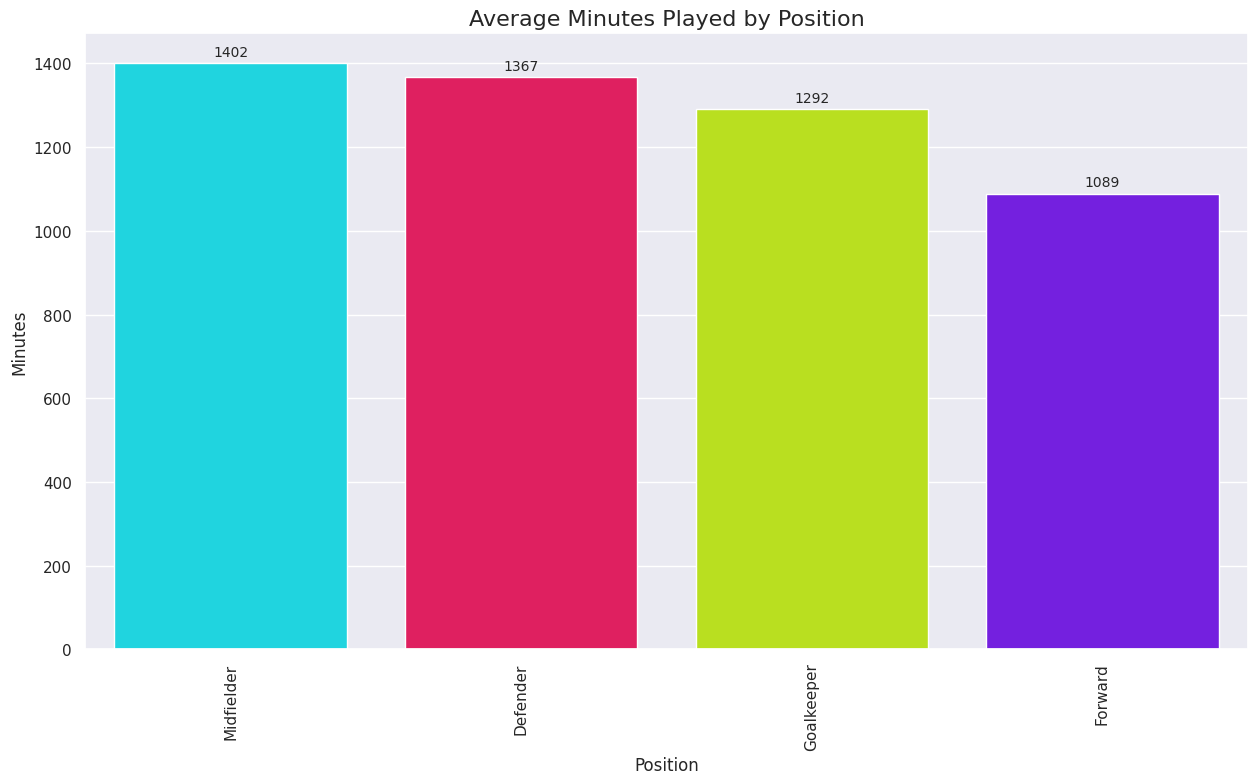

In [ ]:
# Complete the code with the right variables
plt.figure(figsize=(15, 8))
ax = sns.barplot(
    data=df,
    x="Position",
    y="Minutes",
    errorbar=('ci', False),
    palette=cyberpunk_palette,
    order = df.groupby('Position')['Minutes'].mean().sort_values(ascending=False).index
)
plt.xticks(rotation=90)
#Add percentage per bar column
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(f"{height:.0f}",
                (bar.get_x() + bar.get_width() / 2, height),
                ha='center', va='center',
                size=10, xytext=(0,
                                 8),
                textcoords='offset points')
#Add title
plt.title("Average Minutes Played by Position", loc='center', fontsize=16)
plt.show()


**Every point counts in fantasy sports and getting bonus points for a player is always a treat. Let's check which team's players have secured the most bonus points, on average, last season.**

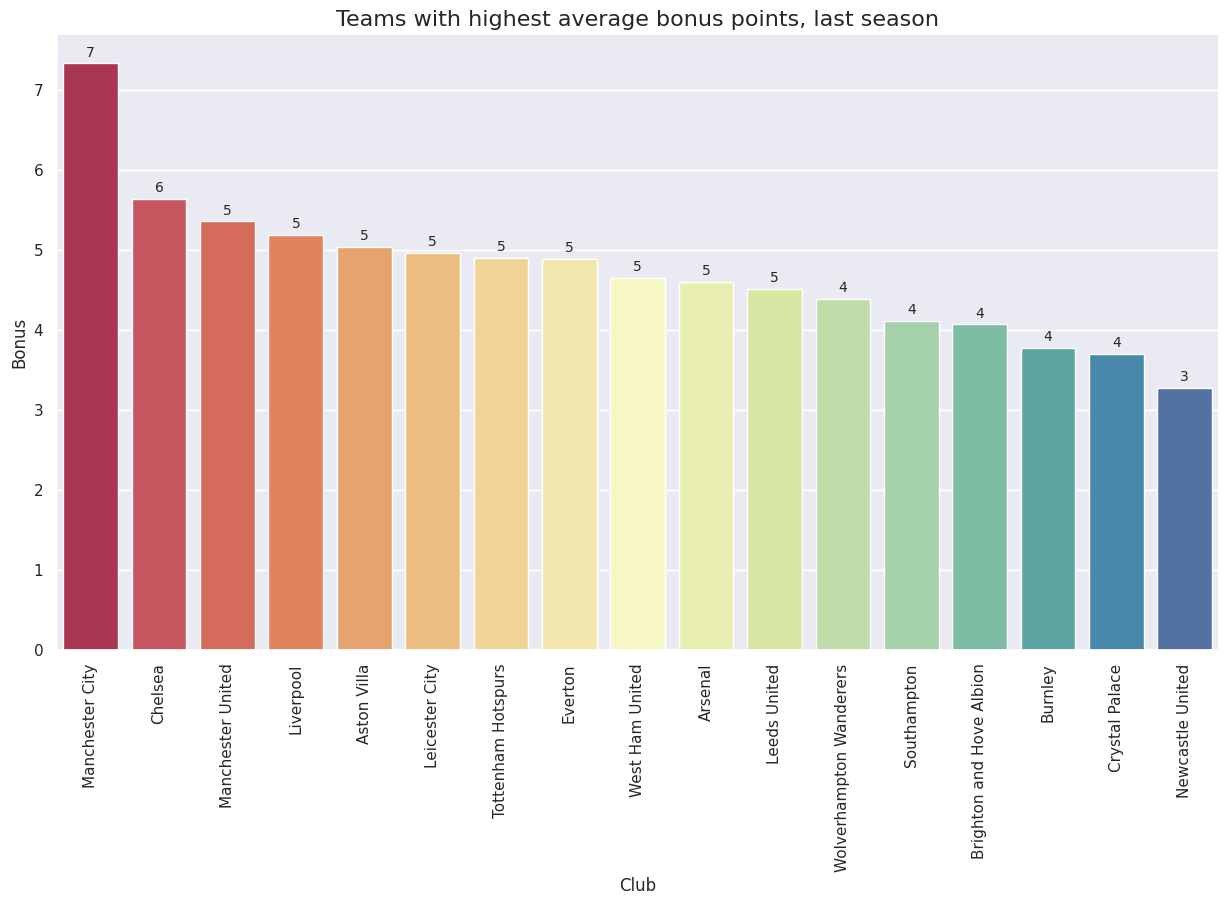

In [ ]:
# Complete the code with the right variables
plt.figure(figsize=(15, 8))
ax = sns.barplot(
    data=df,
    x="Club",
    y="Bonus",
    errorbar=('ci', False),
    palette="Spectral",
    order = df.groupby('Club')['Bonus'].mean().sort_values(ascending=False).index
)
plt.xticks(rotation=90)
#Add percentage per bar column
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(f"{height:.0f}",
                (bar.get_x() + bar.get_width() / 2, height),
                ha='center', va='center',
                size=10, xytext=(0,
                                 8),
                textcoords='offset points')
#Add title
plt.title("Teams with highest average bonus points, last season", loc='center', fontsize=16)
plt.show()


**Let's see which players scored the most fantasy points last season for different positions of play.**

In [ ]:
pos_list = df.Position.unique().tolist()
best_df = pd.DataFrame()

for pos in pos_list:
    df_aux = df[df.Position == pos]
    best_df = pd.concat([best_df, df_aux[df_aux.Total_Points == df_aux.Total_Points.max()][['Player_Name', 'Club', 'Position', 'Total_Points']]])

best_df

,Player_Name,Club,Position,Total_Points
36,Emiliano Martinez,Aston Villa,Goalkeeper,186
403,Harry Kane,Tottenham Hotspurs,Forward,242
315,Bruno Fernandes,Manchester United,Midfielder,244
223,Stuart Dallas,Leeds United,Defender,171


**Let's see the top 10 players with the most fantasy points last season for different positions of play.**

In [ ]:
best10_df = pd.DataFrame()

for pos in pos_list:
    df_aux = df[df.Position == pos]
    best10_df = pd.concat([best10_df, df_aux.sort_values('Total_Points', ascending=False).reset_index(drop=True).loc[:10, ['Player_Name', 'Club', 'Position', 'Total_Points']]])

best10_df

,Player_Name,Club,Position,Total_Points
0,Emiliano Martinez,Aston Villa,Goalkeeper,186
1,Ederson Moares,Manchester City,Goalkeeper,160
2,Illan Meslier,Leeds United,Goalkeeper,154
3,Hugo Lloris,Tottenham Hotspurs,Goalkeeper,149
4,Nick Pope,Burnley,Goalkeeper,144
5,Alisson Becker,Liverpool,Goalkeeper,140
6,Edouard Mendy,Chelsea,Goalkeeper,140
7,Lukasz Fabianski,West Ham United,Goalkeeper,133
8,Rui Pedro Patricio,Wolverhampton Wanderers,Goalkeeper,132
9,Bernd Leno,Arsenal,Goalkeeper,131


### **Outlier Check**

- Let's plot the boxplots of all numerical columns to check for outliers.

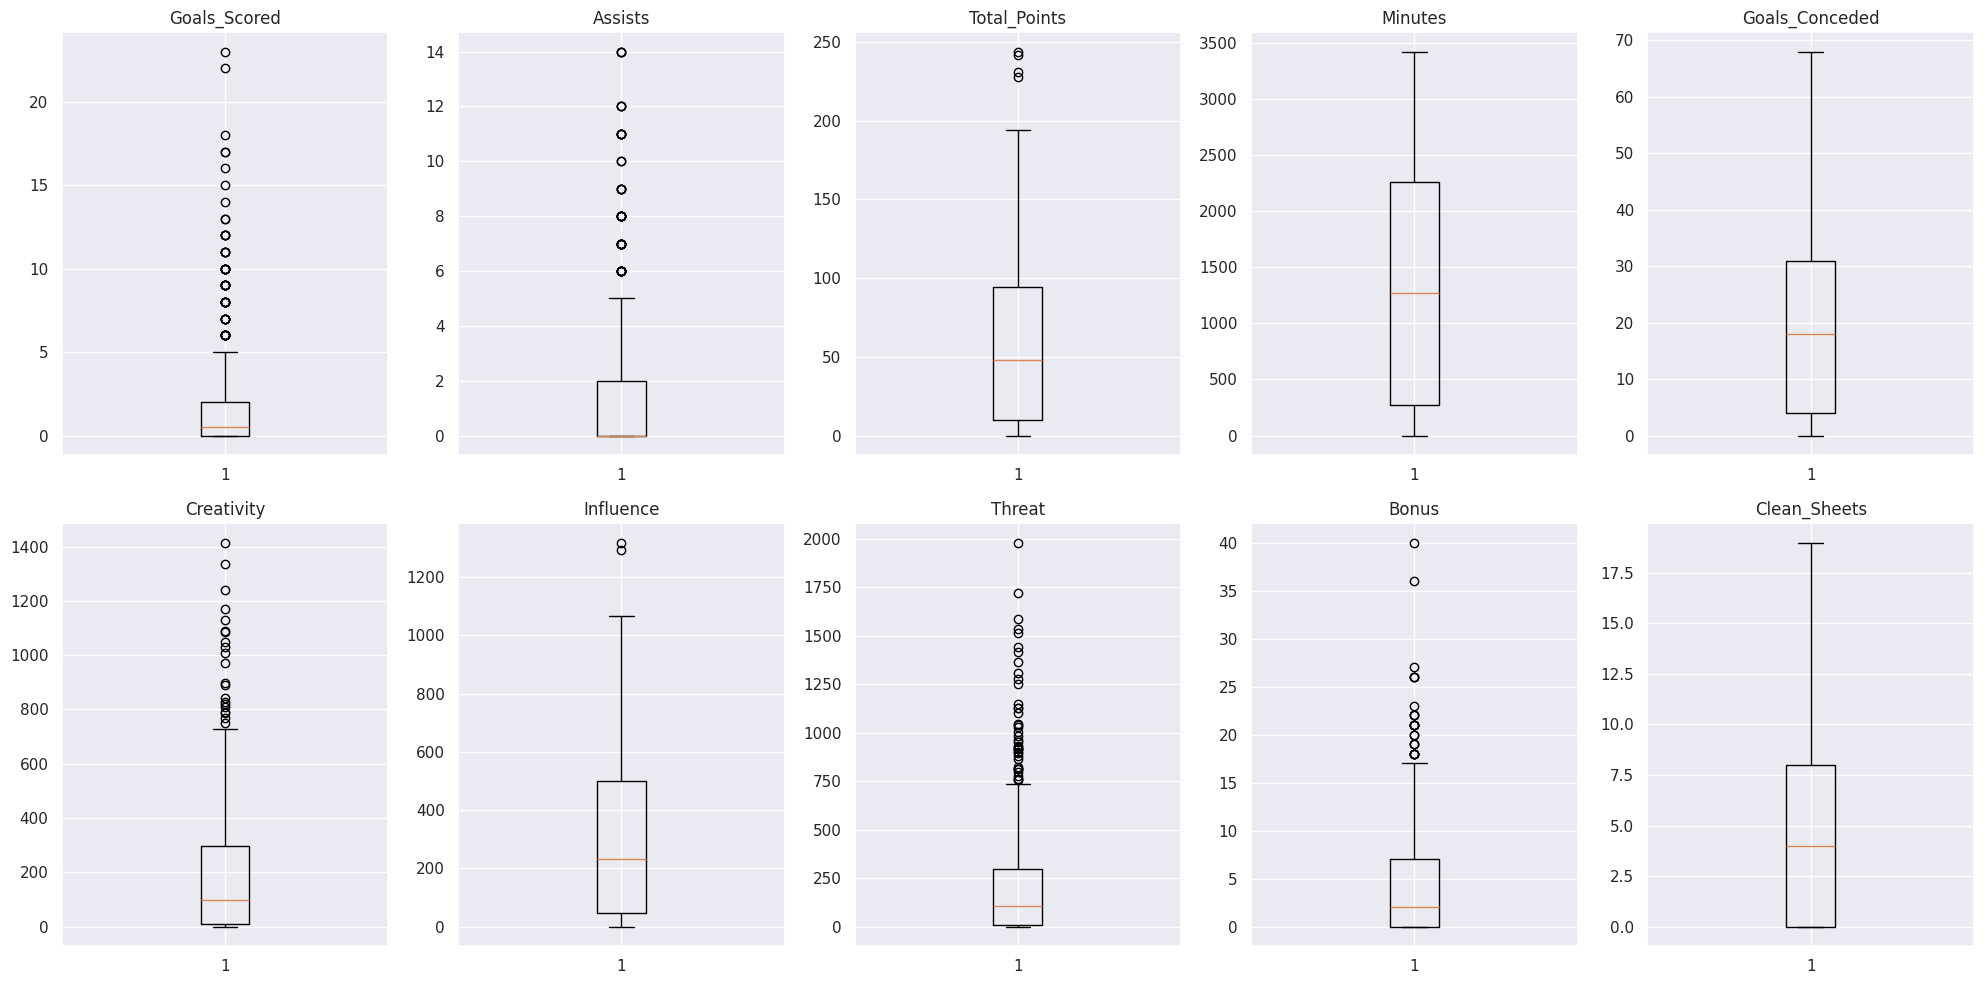

In [ ]:
plt.figure(figsize = (20, 10))

numeric_columns = df.select_dtypes(include = np.number).columns.tolist()

for i, variable in enumerate(numeric_columns):

    plt.subplot(2, 5, i + 1)

    plt.boxplot(df[variable], whis = 1.5)

    plt.tight_layout()

    plt.title(variable)

plt.show()

**Observations from outliers** Outliers are retained in the dataset rather than treated as anomalies or noise. Because these extreme values represent genuine elite performances (such as top-tier goalscorers and high-impact playmakers), they are critical for defining the premium pricing tiers and ensuring the clustering models accurately segment players by potential.

### **Scaling**

- Let's scale the data before we proceed with clustering.

In [ ]:
#Initialize StandardScaler for normalization (Z Score)
scaler = StandardScaler()

#Select only numeric variables
num_cols = df.select_dtypes(include=np.number)

# Adjust and apply transformation
scaled_data = scaler.fit_transform(num_cols)



In [ ]:
# Creas el DataFrame escalado correctamente
subset_scaled_df = pd.DataFrame(scaled_data, columns=num_cols.columns)
subset_scaled_df.head()

,Goals_Scored,Assists,Total_Points,Minutes,Goals_Conceded,Creativity,Influence,Threat,Bonus,Clean_Sheets
0,-0.552608,-0.647555,-1.122506,-1.232383,-1.202653,-0.780115,-1.039325,-0.707638,-0.755435,-1.081123
1,3.213401,0.461208,1.375560,0.539871,0.115663,0.443542,1.150596,1.799393,2.606688,0.513521
2,-0.552608,-0.647555,1.414592,1.672585,1.120094,-0.780115,1.523682,-0.701346,1.005677,1.424747
3,0.895857,1.200384,1.082818,1.134662,0.743432,1.809706,0.741621,2.387618,0.525374,0.741328
4,-0.552608,0.461208,-0.439441,-0.546229,-0.574884,-0.105790,-0.459134,-0.465428,-0.275132,-0.625510


### **Applying PCA**


A dataset with 10 variables (such as the 10 football statistics: goals, assists, minutes played, etc.) might seem useful, but sometimes having that many features brings more noise than value. Managing so many variables at once is complex, and information often repeats (for example, minutes played and goals conceded tend to increase together).

If you can explain player performance using 3 components instead of 10 without losing important information, why complicate things with so many dimensions? That is exactly what PCA allows you to do.

In summary, here is what it does:

1. Finds the directions (axes) where there is the most variation in the data. In other words, it discovers which combination of variables shows us the real differences between players.

2. Reduces noise and discards what doesn't matter: It separates useful information from what just gets in the way.

3. Compresses information: Instead of using the 10 original variables, PCA allows you to summarize them into just a few (for example, only 3 principal components) while retaining almost all of the same information and percentage of variation.

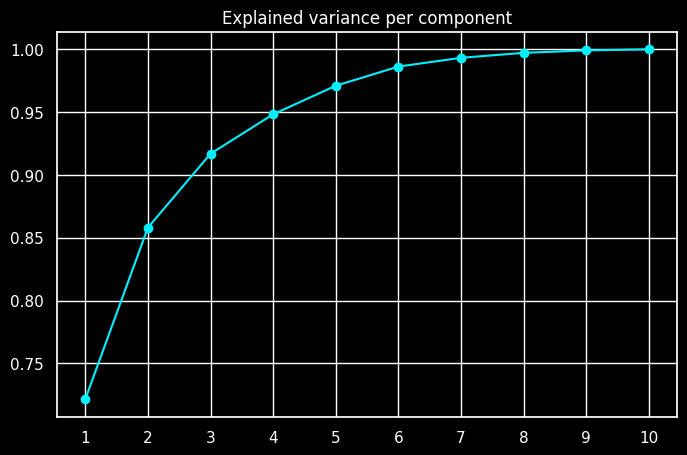

In [ ]:
# 1. Defining the number of features
n = subset_scaled_df.shape[1]

# 2. Initialize PCA with n_components = n and random_state = 1 (any number)
pca = PCA(n_components = n, random_state = 42)

 # 3. Fit_transform PCA on the scaled data and convert it to DataFrame
pca_data = pca.fit_transform(subset_scaled_df)
pca_df = pd.DataFrame(pca_data)

# 4. Get the percentage of variance explained by each principal component is stored
exp_var = pca.explained_variance_ratio_
exp_cumsum = np.cumsum(exp_var)  #Aggregate sum

# Activar fondo oscuro global
plt.style.use("dark_background")

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), exp_cumsum, color="#00f0ff", marker="o")
plt.xticks(np.arange(1, n + 1, 1))
plt.title("Explained variance per component")
plt.show()



In [ ]:
sum(pca.explained_variance_ratio_[:5])

np.float64(0.9710123249796083)

### Interpreting PCA Results

1. **Dimensionality Reduction & Variance Retention:**
   By applying PCA to our 10 original numerical features (goals, assists, minutes, creativity, threat, etc.), we successfully transformed the correlated dataset into principal components without losing critical variance.
2. **Cumulative Explained Variance:**
   As seen in our cumulative variance plot and execution output `[138]`, the first **5 principal components** account for over **97% of the total variance** ($0.9710$). This proves that we successfully compressed our 10-dimensional space into a compact, noise-free representation while preserving nearly all the underlying behavioral patterns of the Premier League players.



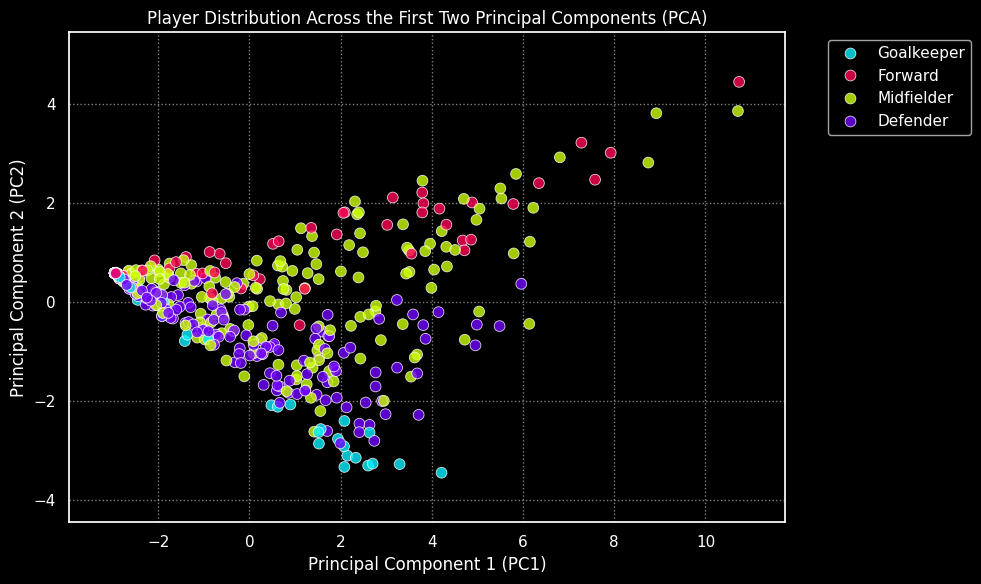

In [ ]:
# 1. Create a temporary DataFrame using the first two principal components from pca_data
pca_2d_df = pd.DataFrame(pca_data[:, :2], columns=['PC1', 'PC2'])
pca_2d_df['Player_Name'] = df['Player_Name']
pca_2d_df['Position'] = df['Position']

# 2. Plot the first two principal components with a cyberpunk style
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=pca_2d_df,
    x='PC1',
    y='PC2',
    hue='Position',
    palette=cyberpunk_palette,
    alpha=0.8,
    s=60
)

# Set explicit limits safely
plt.xlim(pca_2d_df['PC1'].min() - 1, pca_2d_df['PC1'].max() + 1)
plt.ylim(pca_2d_df['PC2'].min() - 1, pca_2d_df['PC2'].max() + 1)

plt.title("Player Distribution Across the First Two Principal Components (PCA)")
plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

This scatter plot in the principal component space (PC1 and PC2) allows for a visual validation of dimensionality reduction, confirming that the 10 original variables project a logical, continuous distribution without noise. Although the unsupervised model does not use prior positional labels, it reveals a natural separation by tactical roles and highlights elite players as outliers in the extremes, validating its use as a stable baseline to feed K-Means centroids. This, however, should not be interpreted as clusters, as they belong to the next clustering techniques.


### Bridging PCA to K-Means Clustering
- Using data_pca instead of raw features prevents redundancy and multicollinearity issues, ensuring that K-Means calculates stable and reliable Euclidean distances. By compressing the information into clean, orthogonal principal components, we can apply the Elbow Method to determine the optimal number of clusters ($K$) and accurately segment player performance.

### K-Means Clustering

The main objective of K-Means is to group the data into $K$ clusters based on similarities between data points. The step-by-step process is as follows:

1. **Define the number of clusters ($K$):**
   We predetermine how many groups ($K$) we want to find in the dataset.
2. **Random initialization of centroids:**
   The algorithm randomly picks $K$ points in the space to act as the initial provisional centers (*centroids*) of the clusters.
3. **Assignment based on minimum distance:**
   It calculates the distance from each data point to each centroid and assigns each point to the group whose centroid is closest.
4. **Update centroids:**
   Once the new groups are formed, the algorithm recomputes the position of each cluster's centroid by taking the average (mean) of all points belonging to that group.
5. **Iteration until convergence:**
   Steps 3 and 4 are repeated iteratively until the algorithm **converges**. This means the centroids stop changing position and points no longer get reassigned to other clusters, achieving complete stability and zero fluctuations.

In [ ]:
k_means_df = pca_df.copy()

Number of Clusters: 1 	Average Distortion: 3.0509085320714706
Number of Clusters: 2 	Average Distortion: 2.1889171518697412
Number of Clusters: 3 	Average Distortion: 1.91635697088183
Number of Clusters: 4 	Average Distortion: 1.3557368359611872
Number of Clusters: 5 	Average Distortion: 1.30586730994045
Number of Clusters: 6 	Average Distortion: 1.2531776349034405
Number of Clusters: 7 	Average Distortion: 1.2270842391445025
Number of Clusters: 8 	Average Distortion: 1.1786538287074606
Number of Clusters: 9 	Average Distortion: 1.134460365850281
Number of Clusters: 10 	Average Distortion: 1.1002742633989953
Number of Clusters: 11 	Average Distortion: 1.0874202248300788
Number of Clusters: 12 	Average Distortion: 1.0785954585850395
Number of Clusters: 13 	Average Distortion: 1.048641972317675
Number of Clusters: 14 	Average Distortion: 1.0360630696073512


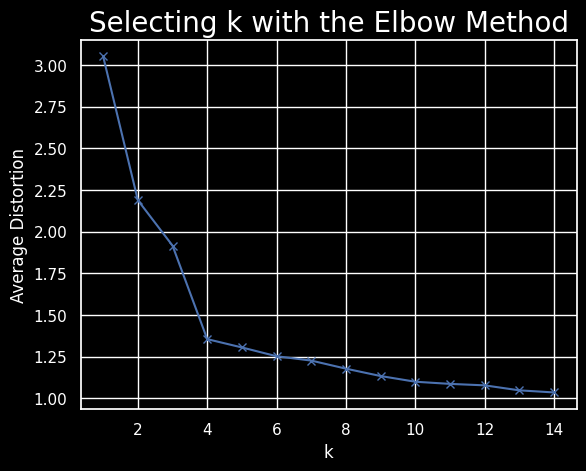

In [ ]:
clusters = range(1, 15)
meanDistortions = []

for k in clusters:

    model = KMeans(n_clusters = k, random_state = 42, n_init = "auto")

    model.fit(k_means_df)

    prediction = model.predict(k_means_df)

    distortion = (
        sum(np.min(cdist(k_means_df, model.cluster_centers_, "euclidean"), axis = 1))
        / k_means_df.shape[0]
    )

    meanDistortions.append(distortion)

    print("Number of Clusters:", k, "\tAverage Distortion:", distortion)

plt.plot(clusters, meanDistortions, "bx-")

plt.xlabel("k")

plt.ylabel("Average Distortion")

plt.title("Selecting k with the Elbow Method", fontsize = 20)

plt.show()

Number of Clusters: 2 	 Silhouette Score: 0.4720
Number of Clusters: 3 	 Silhouette Score: 0.4858
Number of Clusters: 4 	 Silhouette Score: 0.5376
Number of Clusters: 5 	 Silhouette Score: 0.4981
Number of Clusters: 6 	 Silhouette Score: 0.4761
Number of Clusters: 7 	 Silhouette Score: 0.4462
Number of Clusters: 8 	 Silhouette Score: 0.4700
Number of Clusters: 9 	 Silhouette Score: 0.4635
Number of Clusters: 10 	 Silhouette Score: 0.4359
Number of Clusters: 11 	 Silhouette Score: 0.4364
Number of Clusters: 12 	 Silhouette Score: 0.4032
Number of Clusters: 13 	 Silhouette Score: 0.4133
Number of Clusters: 14 	 Silhouette Score: 0.4069


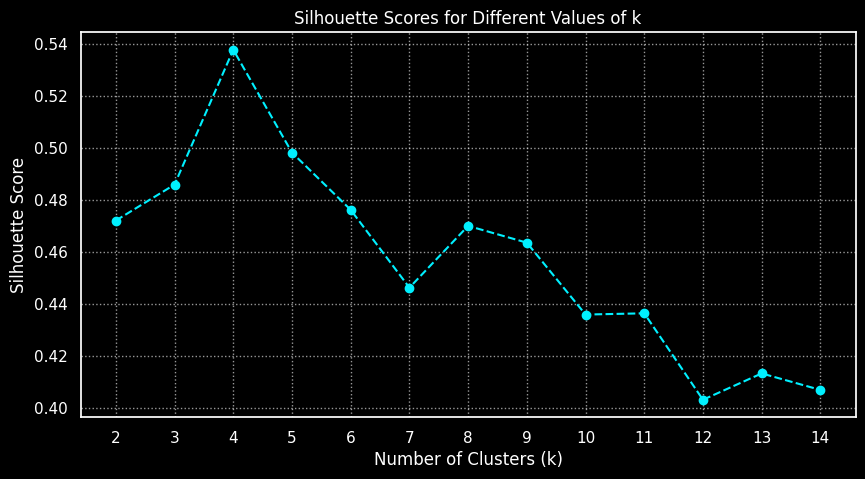

In [ ]:
# 1. Import silhouette metric if not already loaded
from sklearn.metrics import silhouette_score

# 2. Ensure that all column names of k_means_df are converted to strings
k_means_df.columns = k_means_df.columns.astype(str)

# 3. Calculate the Silhouette Score for different values of k
sil_scores = []
K_range = range(2, 15)  # Silhouette score requires at least k=2

for k in K_range:
    model = KMeans(n_clusters=k, random_state=42, n_init="auto")
    preds = model.fit_predict(k_means_df)
    score = silhouette_score(k_means_df, preds)
    sil_scores.append(score)
    print(f"Number of Clusters: {k} \t Silhouette Score: {score:.4f}")

# 4. Plot the Silhouette scores
plt.figure(figsize=(10, 5))
plt.plot(K_range, sil_scores, marker='o', linestyle='--', color='#00f0ff')
plt.title("Silhouette Scores for Different Values of k")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(np.arange(2, 15, 1))
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

**Observations and Insights:**

- We will move ahead with k = 4.
**Observations and Insights:**
- We will move ahead with $k = 4$.
- **Why?** In the average distortion plot, as the number of clusters ($k$) increases, distortion decreases. However, around $k = 4$, the curve bends sharply to form an "elbow." Beyond $k = 4$, adding more clusters results in a much slower, more gradual decrease in distortion, indicating diminishing returns. Furthermore, the silhouette score peaks at $k = 4$ ($0.5376$), confirming it as the optimal balance for well-separated, compact clusters.
Methodological note:
- **Average Distortion (Elbow Method):** Measures cluster compactness via average squared distance to centroids. Lower values indicate tighter clusters. We look for an **"elbow point"** where the rate of decrease sharply slows down, balancing model complexity and compactness.
- **Silhouette Score:** Measures how similar a point is to its own cluster compared to others, ranging from **-1 to +1**. Higher scores indicate denser, well-separated clusters, confirming the optimal number of groups at its peak.

In [ ]:
kmeans = KMeans(4, random_state = 1, n_init = "auto") # Create K-Means with nclusters = 4

kmeans.fit(k_means_df)

KMeans(n_clusters=4, random_state=1)

In [ ]:

# Creating a copy of the original data
df1 = df.copy()
#Which cluster belong each player/datapoint?
# Adding K-Means cluster labels to the K-Means dataframe
k_means_df["KM_segments"] = kmeans.labels_

# Adding K-Means cluster labels to the original dataframe
df1["KM_segments"] = kmeans.labels_
df1.head()

,Player_Name,Club,Position,Goals_Scored,Assists,Total_Points,Minutes,Goals_Conceded,Creativity,Influence,Threat,Bonus,Clean_Sheets,KM_segments
0,Alex Runnarsson,Arsenal,Goalkeeper,0,0,1,15,0,0.0,16.6,0,0,0,1
1,Alexandre Lacazette,Arsenal,Forward,13,3,129,1916,21,307.4,602.4,797,21,7,2
2,Bernd Leno,Arsenal,Goalkeeper,0,0,131,3131,37,0.0,702.2,2,11,11,0
3,Bukayo Saka,Arsenal,Midfielder,5,5,114,2554,31,650.6,493.0,984,8,8,2
4,Calum Chambers,Arsenal,Defender,0,3,36,751,10,169.4,171.8,77,3,2,3


### **Cluster Profiling**

In [ ]:
# What are the average features per cluster?
km_cluster_profile = df1.groupby("KM_segments").mean(numeric_only = True)  # Complete the code to groupby the cluster labels
km_cluster_profile

,Goals_Scored,Assists,Total_Points,Minutes,Goals_Conceded,Creativity,Influence,Threat,Bonus,Clean_Sheets
KM_segments,,,,,,,,,,
0,1.363636,1.878788,103.525253,2670.555556,37.525253,265.671717,579.185859,199.636364,7.676768,10.020202
1,0.148936,0.202128,9.824468,238.750000,3.930851,28.171809,43.164894,30.244681,0.409574,0.558511
2,9.183333,6.716667,142.150000,2457.266667,33.516667,623.141667,664.133333,880.533333,16.266667,9.250000
3,1.503876,1.604651,56.038760,1392.736434,20.573643,188.358915,270.818605,223.255814,3.356589,4.705426


In [ ]:
#How many data points/players exist per cluster?
# Creating the "count_in_each_segment" feature in K-Means cluster profile

km_cluster_profile["count_in_each_segment"] = (
    df1.groupby("KM_segments")["Total_Points"].count().values)  # Complete the code to groupby the cluster labels
km_cluster_profile

,Goals_Scored,Assists,Total_Points,Minutes,Goals_Conceded,Creativity,Influence,Threat,Bonus,Clean_Sheets,count_in_each_segment
KM_segments,,,,,,,,,,,
0,1.363636,1.878788,103.525253,2670.555556,37.525253,265.671717,579.185859,199.636364,7.676768,10.020202,99
1,0.148936,0.202128,9.824468,238.750000,3.930851,28.171809,43.164894,30.244681,0.409574,0.558511,188
2,9.183333,6.716667,142.150000,2457.266667,33.516667,623.141667,664.133333,880.533333,16.266667,9.250000,60
3,1.503876,1.604651,56.038760,1392.736434,20.573643,188.358915,270.818605,223.255814,3.356589,4.705426,129


In [ ]:
#What are the maximum values for each feature in each cluster?
# Highlight the maximum average value among all the clusters for each of the variables
km_cluster_profile.style.highlight_max(color = "darkgreen", axis = 0)

,Goals_Scored,Assists,Total_Points,Minutes,Goals_Conceded,Creativity,Influence,Threat,Bonus,Clean_Sheets,count_in_each_segment
KM_segments,,,,,,,,,,,
0,1.363636,1.878788,103.525253,2670.555556,37.525253,265.671717,579.185859,199.636364,7.676768,10.020202,99
1,0.148936,0.202128,9.824468,238.750000,3.930851,28.171809,43.164894,30.244681,0.409574,0.558511,188
2,9.183333,6.716667,142.150000,2457.266667,33.516667,623.141667,664.133333,880.533333,16.266667,9.250000,60
3,1.503876,1.604651,56.038760,1392.736434,20.573643,188.358915,270.818605,223.255814,3.356589,4.705426,129


In [ ]:
#What are the min values for each feature in each cluster?
# Highlight the min average value among all the clusters for each of the variables
km_cluster_profile.style.highlight_min(color = "darkgreen", axis = 0)

,Goals_Scored,Assists,Total_Points,Minutes,Goals_Conceded,Creativity,Influence,Threat,Bonus,Clean_Sheets,count_in_each_segment
KM_segments,,,,,,,,,,,
0,1.363636,1.878788,103.525253,2670.555556,37.525253,265.671717,579.185859,199.636364,7.676768,10.020202,99
1,0.148936,0.202128,9.824468,238.750000,3.930851,28.171809,43.164894,30.244681,0.409574,0.558511,188
2,9.183333,6.716667,142.150000,2457.266667,33.516667,623.141667,664.133333,880.533333,16.266667,9.250000,60
3,1.503876,1.604651,56.038760,1392.736434,20.573643,188.358915,270.818605,223.255814,3.356589,4.705426,129


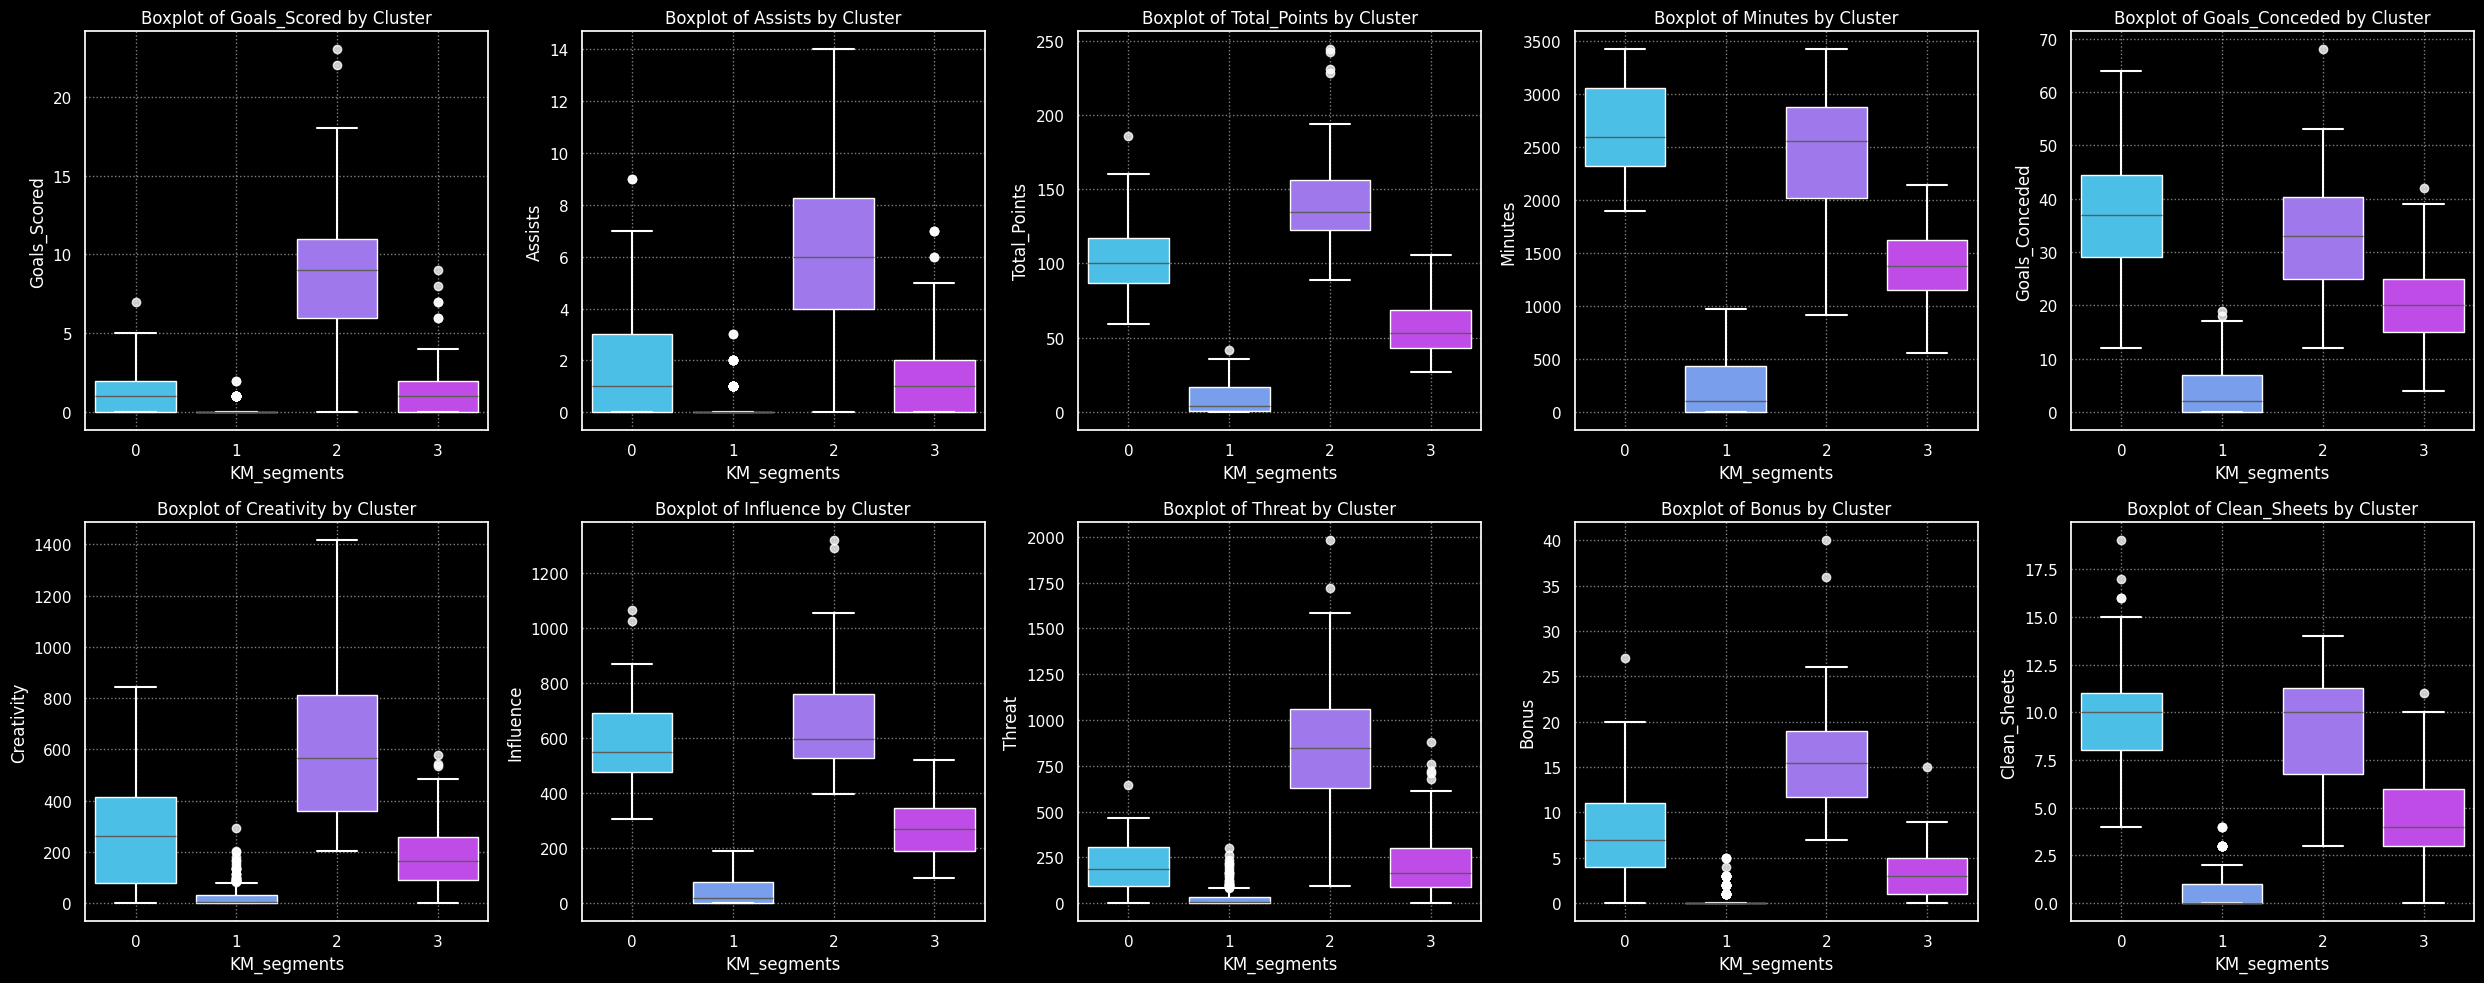

In [ ]:
# Create a clean grid of boxplots with white outliers and whiskers for the first 10 numerical columns
fig, axes = plt.subplots(2, 5, figsize=(25, 10))
axes = axes.flatten() # Flatten to easily iterate with a single loop

numeric_cols_list = df1.select_dtypes(include=np.number).columns.tolist()
# Exclude the segment label from the features to plot
features_to_plot = [col for col in numeric_cols_list if col != 'KM_segments'][:10]

for i, feature in enumerate(features_to_plot):
    sns.boxplot(
        data=df1,
        x="KM_segments",
        y=feature,
        ax=axes[i],
        palette="cool",
        # Customizing colors: white outliers (flierprops) and white whiskers/caps
        flierprops={'markerfacecolor': '#ffffff', 'markeredgecolor': '#ffffff', 'marker': 'o', 'alpha': 0.8},
        boxprops={'edgecolor': '#ffffff'},
        whiskerprops={'color': '#ffffff', 'linewidth': 1.5},
        capprops={'color': '#ffffff', 'linewidth': 1.5}
    )
    axes[i].set_title(f"Boxplot of {feature} by Cluster", color='#ffffff')
    axes[i].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
#Which players are present in each cluster?
# Complete the code to print the players in each cluster. Hint: Use the KM_segments feature
for cl in df1["KM_segments"].unique():
    print("In cluster {}, the following players are present:".format(cl))
    print(df1[df1["KM_segments"] == cl]["Player_Name"].unique())
    print()

In cluster 1, the following players are present:
['Alex Runnarsson' 'Cedric Soares' 'Edward Nketiah'
 'Gabriel Teodoro Martinelli Silva' 'Matt Macey' 'Miguel Azeez'
 'Pablo Mari' 'Reiss Nelson' 'Sead Kolasinac' 'Shkodran Mustafi'
 'Sokratis Papastathopoulos' 'William Saliba' 'Ahmed El Mohamady'
 'Carney Chukwuemeka' 'Conor Hourihane' 'Henri Lansbury' 'Jacob Ramsey'
 'Jaden Philogene-Bidace' 'Jose Peleteiro Romallo' 'Keinan Davis'
 'Kortney Hause' 'Marvelous Nakamba' 'Morgan Sanson' 'Orjan Nyland'
 'Wesley Moraes' 'Alireza Jahanbakhsh' 'Andi Zeqiri'
 'Bernardo Fernandes da Silva Junior' 'Davy Propper' 'Jakub Moder'
 'Jason Steele' 'Jayson Molumby' 'Jose Izquierdo' 'Percy Tau'
 'Reda Khadra' 'Anthony Driscoll-Glennon' 'Bailey Peacock-Farrell'
 'Dale Stephens' 'Jimmy Dunne' 'Joel Mumbongo' 'Josh Benson' 'Kevin Long'
 'Lewis Richardson' 'Phil Bardsley' 'Will Norris' 'Billy Gilmour'
 'Emerson Palmieri dos Santos' 'Faustino Anjorin' 'Fikayo Tomori'
 'Karlo Ziger' 'Kepa Arrizabalaga' 'Valenti

In [ ]:
df1.groupby(["KM_segments", "Position"])['Player_Name'].count()

KM_segments  Position  
0            Defender      50
             Goalkeeper    17
             Midfielder    32
1            Defender      70
             Forward       28
             Goalkeeper    25
             Midfielder    65
2            Defender       5
             Forward       20
             Midfielder    35
3            Defender      47
             Forward       16
             Goalkeeper     3
             Midfielder    63
Name: Player_Name, dtype: int64

- **Executive Summary ($K=4$):** The K-Means segmentation identifies four distinct player profiles:
0. Cluster 0 represents reliable defensive anchors and high-minute starters (99 players);
1. Cluster 1 forms the baseline "enablers" and squad rotation reserves with minimal minutes (188 players);
2. Cluster 2 captures the elite offensive and creative playmakers who drive maximum points (60 players); and
3. Cluster 3 consists of regular mid-table and rotational starters (129 players).

- **Positional & Performance Dynamics:** Elite productivity is heavily concentrated in Cluster 2, where top-tier midfielders and forwards maximize threat, creativity, and bonus points (averaging ~142.1 total points). Conversely, defensive stability and maximum durability dominate Cluster 0 through heavy clean-sheet accumulation and high minutes, while Cluster 1 acts as a low-cost budget pool.
- **Strategic Pricing & Business Value:** To price players optimally for the upcoming season on OnSports, the platform could implement an exponential pricing strategy—commanding premium valuations for the elite performers in Cluster 2, establishing baseline minimum prices for the widespread enablers in Cluster 1 to balance user budgets, and assigning mid-tier pricing to the stable defensive (Cluster 0) and rotational assets (Cluster 3).

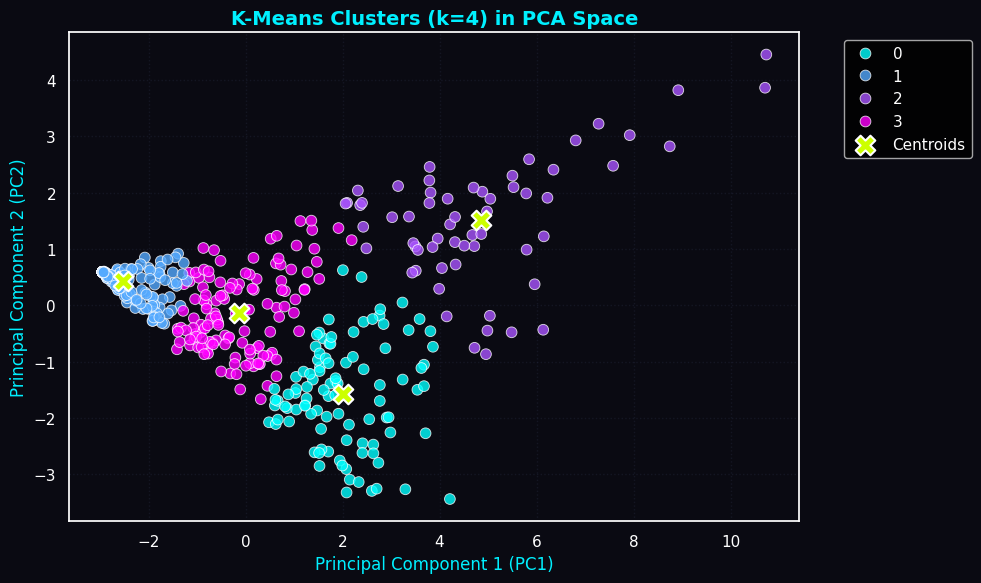

In [248]:
#Visualize clusters made with K.means
# 1. Prepare data for plotting
plot_df = pd.DataFrame(pca_data[:, :2], columns=['PC1', 'PC2'])
plot_df['KM_segments'] = kmeans.labels_
plot_df['Player_Name'] = df['Player_Name']

# 2. Get cluster centroids in PCA space
centroids = kmeans.cluster_centers_[:, :2]

# 3. Plotting with a clean dark theme matching your notebook
plt.style.use('dark_background')
plt.figure(figsize=(10, 6), facecolor='#0a0a12')
ax = plt.axes()
ax.set_facecolor('#0a0a12')

# Scatter plot of players colored by cluster
sns.scatterplot(
    data=plot_df,
    x='PC1',
    y='PC2',
    hue='KM_segments',
    palette='cool',
    alpha=0.8,
    s=60,
    legend='full',
    ax=ax
)

# Plot the K-Means centroids as distinct markers (large white/gold 'X')
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker='X',
    s=200,
    color='#ccff00',
    edgecolors='#ffffff',
    linewidths=1.5,
    label='Centroids',
    zorder=5
)

plt.title("K-Means Clusters (k=4) in PCA Space", fontsize=14, color='#00f0ff', fontweight='bold')
plt.xlabel("Principal Component 1 (PC1)", color='#00f0ff')
plt.ylabel("Principal Component 2 (PC2)", color='#00f0ff')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle=':', alpha=0.5, color='#1f2335')
plt.tight_layout()
plt.show()

# Revert style if needed
plt.style.use('default')
sns.set_theme(style='darkgrid')

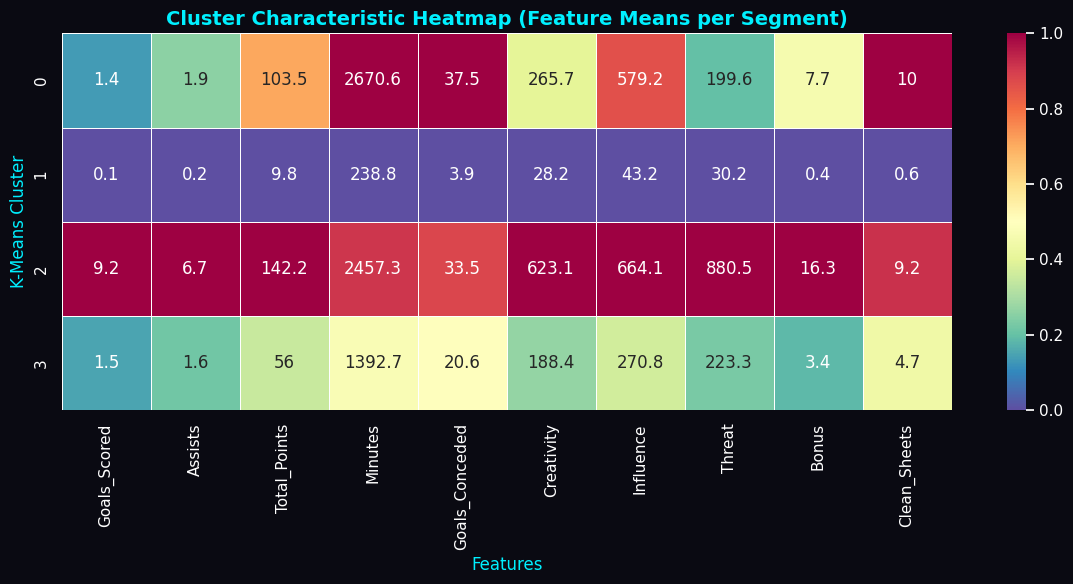

In [250]:
# Calculate mean values per cluster on original numeric features
profile_heatmap = df1.groupby('KM_segments')[numeric_columns].mean()

# Normalize across columns to see relative strengths per cluster
normalized_profile = (profile_heatmap - profile_heatmap.min()) / (profile_heatmap.max() - profile_heatmap.min())

plt.style.use('dark_background')
plt.figure(figsize=(12, 6), facecolor='#0a0a12')
ax = plt.axes()
ax.set_facecolor('#0a0a12')

sns.heatmap(
    normalized_profile,
    annot=profile_heatmap.round(1), # Show actual values inside the cells
    fmt='g',
    cmap='Spectral_r',
    linewidths=0.5,
    cbar=True,
    ax=ax
)

plt.title("Cluster Characteristic Heatmap (Feature Means per Segment)", color='#00f0ff', fontsize=14, fontweight='bold')
plt.xlabel("Features", color='#00f0ff')
plt.ylabel("K-Means Cluster", color='#00f0ff')
plt.tight_layout()
plt.show()

plt.style.use('default')
sns.set_theme(style='darkgrid')

Insights from K-Means Clustering Visualizations

1) 2D Cluster Scatter Plot with Centroids (Plot 1)
- Spatial Separation: The projection across PC1 and PC2 confirms that
𝑘=4 successfully partitions players into distinct, non-overlapping groups.

- Cluster Differentiation: Cluster 2 isolates elite attackers/playmakers on the positive extremes, while baseline squad enablers (Cluster 1) cluster tightly near the origin.

- Centroid Stability: The gold/white 'X' markers sit at the center of mass for each group, validating the mathematical stability of the clusters in PCA space.
- Positional Diversity within Clusters: Clusters are driven by performance and playing time rather than rigid tactical roles, proving that data-driven groupings transcend baseline positions.

2. Cluster Characteristic Heatmap & Feature Pairplots (Plots 2 & 3)
- Translating PCA: Grounding the reduced dimensions back into raw stats makes cluster logic transparent for pricing strategies.

- Elite Tier Justification: Cluster 2 spikes across Goals, Threat, Creativity, and Bonus points (~142.1 average points), justifying premium pricing.

- Defensive & Squad Baselines: Cluster 0 captures reliable defensive anchors (high minutes and clean sheets), while Cluster 1 represents low-minute squad reserves.

## **K-Medoids Clustering**
K-Medoids is an adjustment or variation of K-Means where the cluster center must be an actual data point from the dataset (a medoid). In standard K-Means, the cluster center is the mathematical mean of the data points in each cluster, which is not necessarily a real data point itself. In K-Medoids, the center has to be one of the actual observations. For this implementation, we use the scikit-learn-extra library (sklearn_extra.cluster).

In [253]:
kmed_df = pca_df.copy()

In [254]:
kmed = KMedoids(n_clusters=4, random_state = 42) # Create K-Medoids with nclusters = 4
kmed.fit(kmed_df)

KMedoids(n_clusters=4, random_state=42)

In [259]:
#Getting the clusters' centers or medoids
pd.DataFrame(kmed.cluster_centers_)

,0,1,2,3,4,5,6,7,8,9
0,3.510462,0.613016,0.517543,0.416560,0.191936,-0.405614,-0.116210,-0.279499,0.004610,-0.033056
1,1.672802,-1.977894,-0.210775,0.195068,0.267424,0.657495,0.063915,0.153208,-0.127187,0.002233
2,-0.602559,0.081585,0.174035,-0.050390,0.372458,-0.167053,0.230252,-0.107574,0.052573,-0.026930
3,-2.879568,0.536520,-0.041019,0.160248,-0.023890,0.007384,-0.032287,0.029865,-0.025391,-0.016262


In [266]:
#Previous is hard to read because it is the original dataframe after PCA transformation and scaler transformation
#We can reverse the transformation just to proof that the new cluster's centers selected by K_Mediods are actual people
medoids_original = pd.DataFrame(
    scaler.inverse_transform(pca.inverse_transform(kmed.cluster_centers_)),
    columns=num_cols.columns
)

# Medoids translated in original values (each medoid is a real player with its features' metrics)
medoids_original

,Goals_Scored,Assists,Total_Points,Minutes,Goals_Conceded,Creativity,Influence,Threat,Bonus,Clean_Sheets
0,6.000000e+00,5.000000e+00,122.0,2244.0,29.0,644.2,530.6,5.100000e+02,1.300000e+01,1.000000e+01
1,-2.886580e-15,2.000000e+00,100.0,2683.0,35.0,84.3,610.4,1.520000e+02,7.000000e+00,1.100000e+01
2,1.000000e+00,1.000000e+00,48.0,1108.0,14.0,210.6,170.6,2.350000e+02,3.000000e+00,5.000000e+00
3,2.220446e-16,1.998401e-15,3.0,45.0,1.0,1.0,11.6,2.557954e-13,8.881784e-16,-8.881784e-16


In [278]:
#Who are the data points(players) that serve as clusters' centers per each group?
#Cluster 0, for instance, says that it is a person who schored 6 goals, assisted 5 and had 122 points, who might he be?
df[(df["Goals_Scored"] == 6) & (df["Assists"] == 5) & (df["Total_Points"]== 122)]

,Player_Name,Club,Position,Goals_Scored,Assists,Total_Points,Minutes,Goals_Conceded,Creativity,Influence,Threat,Bonus,Clean_Sheets
179,Gylfi Sigurdsson,Everton,Midfielder,6,5,122,2244,29,644.2,530.6,510,13,10


In [275]:
#As predicted, the center of cluster one is a real player and his name is Gylfi Sigurdsoon. Let's get the name of all players that serve as centers
print("Players that serve as clusters' centers (Medoids\n")
for i, medoid in enumerate(medoids_original.values):
    # Encontramos la fila en el DataFrame original que más se aproxime a los valores del medoid
    match = df[
        (df["Goals_Scored"].round(0) == round(medoid[0])) &
        (df["Assists"].round(0) == round(medoid[1])) &
        (df["Total_Points"].round(0) == round(medoid[2]))
    ]
    if not match.empty:
        player = match.iloc[0]
        print(f"Clúster {i}: {player['Player_Name']} ({player['Club']} - {player['Position']})")
    else:
        print(f"Clúster {i}: (Coincidencia exacta por redondeo no encontrada)")


Players that serve as clusters' centers (Medoids

Clúster 0: Gylfi Sigurdsson (Everton - Midfielder)
Clúster 1: Ben Godfrey (Everton - Defender)
Clúster 2: Alexis Mac Allister (Brighton and Hove Albion - Midfielder)
Clúster 3: Shkodran Mustafi (Arsenal - Defender)


In [276]:
# Creating a copy of the original data
df2 = df.copy()

# Add K-Medoids cluster labels to K-Medoids data
k_med_df["KMed_segments"] = kmed.labels_

# Add K-Medoids cluster labels to original data
df2["KMed_segments"] = kmed.labels_
df2.head()

,Player_Name,Club,Position,Goals_Scored,Assists,Total_Points,Minutes,Goals_Conceded,Creativity,Influence,Threat,Bonus,Clean_Sheets,KMed_segments
0,Alex Runnarsson,Arsenal,Goalkeeper,0,0,1,15,0,0.0,16.6,0,0,0,3
1,Alexandre Lacazette,Arsenal,Forward,13,3,129,1916,21,307.4,602.4,797,21,7,0
2,Bernd Leno,Arsenal,Goalkeeper,0,0,131,3131,37,0.0,702.2,2,11,11,1
3,Bukayo Saka,Arsenal,Midfielder,5,5,114,2554,31,650.6,493.0,984,8,8,0
4,Calum Chambers,Arsenal,Defender,0,3,36,751,10,169.4,171.8,77,3,2,2


### **Cluster Profiling**

In [277]:
# Take the cluster-wise mean of all the variables. Hint: First group 'df2' by cluster labels column and then find mean
km_cluster_profile = df2.groupby("KMed_segments").mean(numeric_only = True)  #
km_cluster_profile

,Goals_Scored,Assists,Total_Points,Minutes,Goals_Conceded,Creativity,Influence,Threat,Bonus,Clean_Sheets
KMed_segments,,,,,,,,,,
0,7.512195,6.195122,133.243902,2452.243902,33.853659,602.902439,625.653659,745.402439,14.573171,9.231707
1,1.068966,1.091954,99.528736,2638.195402,36.632184,184.582759,575.818391,166.333333,6.988506,9.931034
2,1.338235,1.558824,51.073529,1270.051471,18.977941,180.458824,242.588235,203.102941,2.904412,4.205882
3,0.099415,0.111111,7.736842,193.187135,3.362573,18.979532,34.188304,22.608187,0.280702,0.385965


In [288]:
# Create the "count_in_each_segment" column in K-Medoids cluster profile
km_cluster_profile["count_in_each_segment"] = df2.groupby("KMed_segments")["Player_Name"].count()
km_cluster_profile

,Goals_Scored,Assists,Total_Points,Minutes,Goals_Conceded,Creativity,Influence,Threat,Bonus,Clean_Sheets,count_in_each_segment
KMed_segments,,,,,,,,,,,
0,7.512195,6.195122,133.243902,2452.243902,33.853659,602.902439,625.653659,745.402439,14.573171,9.231707,82
1,1.068966,1.091954,99.528736,2638.195402,36.632184,184.582759,575.818391,166.333333,6.988506,9.931034,87
2,1.338235,1.558824,51.073529,1270.051471,18.977941,180.458824,242.588235,203.102941,2.904412,4.205882,136
3,0.099415,0.111111,7.736842,193.187135,3.362573,18.979532,34.188304,22.608187,0.280702,0.385965,171


In [290]:
# Highlight the maximum average value among all the clusters for each of the variables
km_cluster_profile.style.highlight_max(color = "magenta", axis = 0)

,Goals_Scored,Assists,Total_Points,Minutes,Goals_Conceded,Creativity,Influence,Threat,Bonus,Clean_Sheets,count_in_each_segment
KMed_segments,,,,,,,,,,,
0,7.512195,6.195122,133.243902,2452.243902,33.853659,602.902439,625.653659,745.402439,14.573171,9.231707,82
1,1.068966,1.091954,99.528736,2638.195402,36.632184,184.582759,575.818391,166.333333,6.988506,9.931034,87
2,1.338235,1.558824,51.073529,1270.051471,18.977941,180.458824,242.588235,203.102941,2.904412,4.205882,136
3,0.099415,0.111111,7.736842,193.187135,3.362573,18.979532,34.188304,22.608187,0.280702,0.385965,171


In [291]:
# Complete the code to print the players in each cluster. Hint: Use the KMed_segments feature
for cl in df2["KMed_segments"].unique():
    print("In cluster {}, the following players are present:".format(cl))
    print(df2[df2["KMed_segments"] == cl]["Player_Name"].unique())
    print()

In cluster 3, the following players are present:
['Alex Runnarsson' 'Matt Macey' 'Miguel Azeez' 'Reiss Nelson'
 'Sead Kolasinac' 'Shkodran Mustafi' 'Sokratis Papastathopoulos'
 'William Saliba' 'Carney Chukwuemeka' 'Conor Hourihane' 'Henri Lansbury'
 'Jacob Ramsey' 'Jaden Philogene-Bidace' 'Jose Peleteiro Romallo'
 'Keinan Davis' 'Kortney Hause' 'Morgan Sanson' 'Orjan Nyland'
 'Wesley Moraes' 'Alireza Jahanbakhsh' 'Andi Zeqiri'
 'Bernardo Fernandes da Silva Junior' 'Davy Propper' 'Jakub Moder'
 'Jason Steele' 'Jayson Molumby' 'Jose Izquierdo' 'Percy Tau'
 'Reda Khadra' 'Anthony Driscoll-Glennon' 'Bailey Peacock-Farrell'
 'Dale Stephens' 'Jimmy Dunne' 'Joel Mumbongo' 'Josh Benson' 'Kevin Long'
 'Lewis Richardson' 'Phil Bardsley' 'Will Norris' 'Billy Gilmour'
 'Emerson Palmieri dos Santos' 'Faustino Anjorin' 'Fikayo Tomori'
 'Karlo Ziger' 'Kepa Arrizabalaga' 'Valentino Livramento'
 'Willy Caballero' 'Connor Wickham' 'Jack Butland' 'James McCarthy'
 'James Tomkins' 'Jean-Philippe Mateta' 

**Let's plot the boxplot**

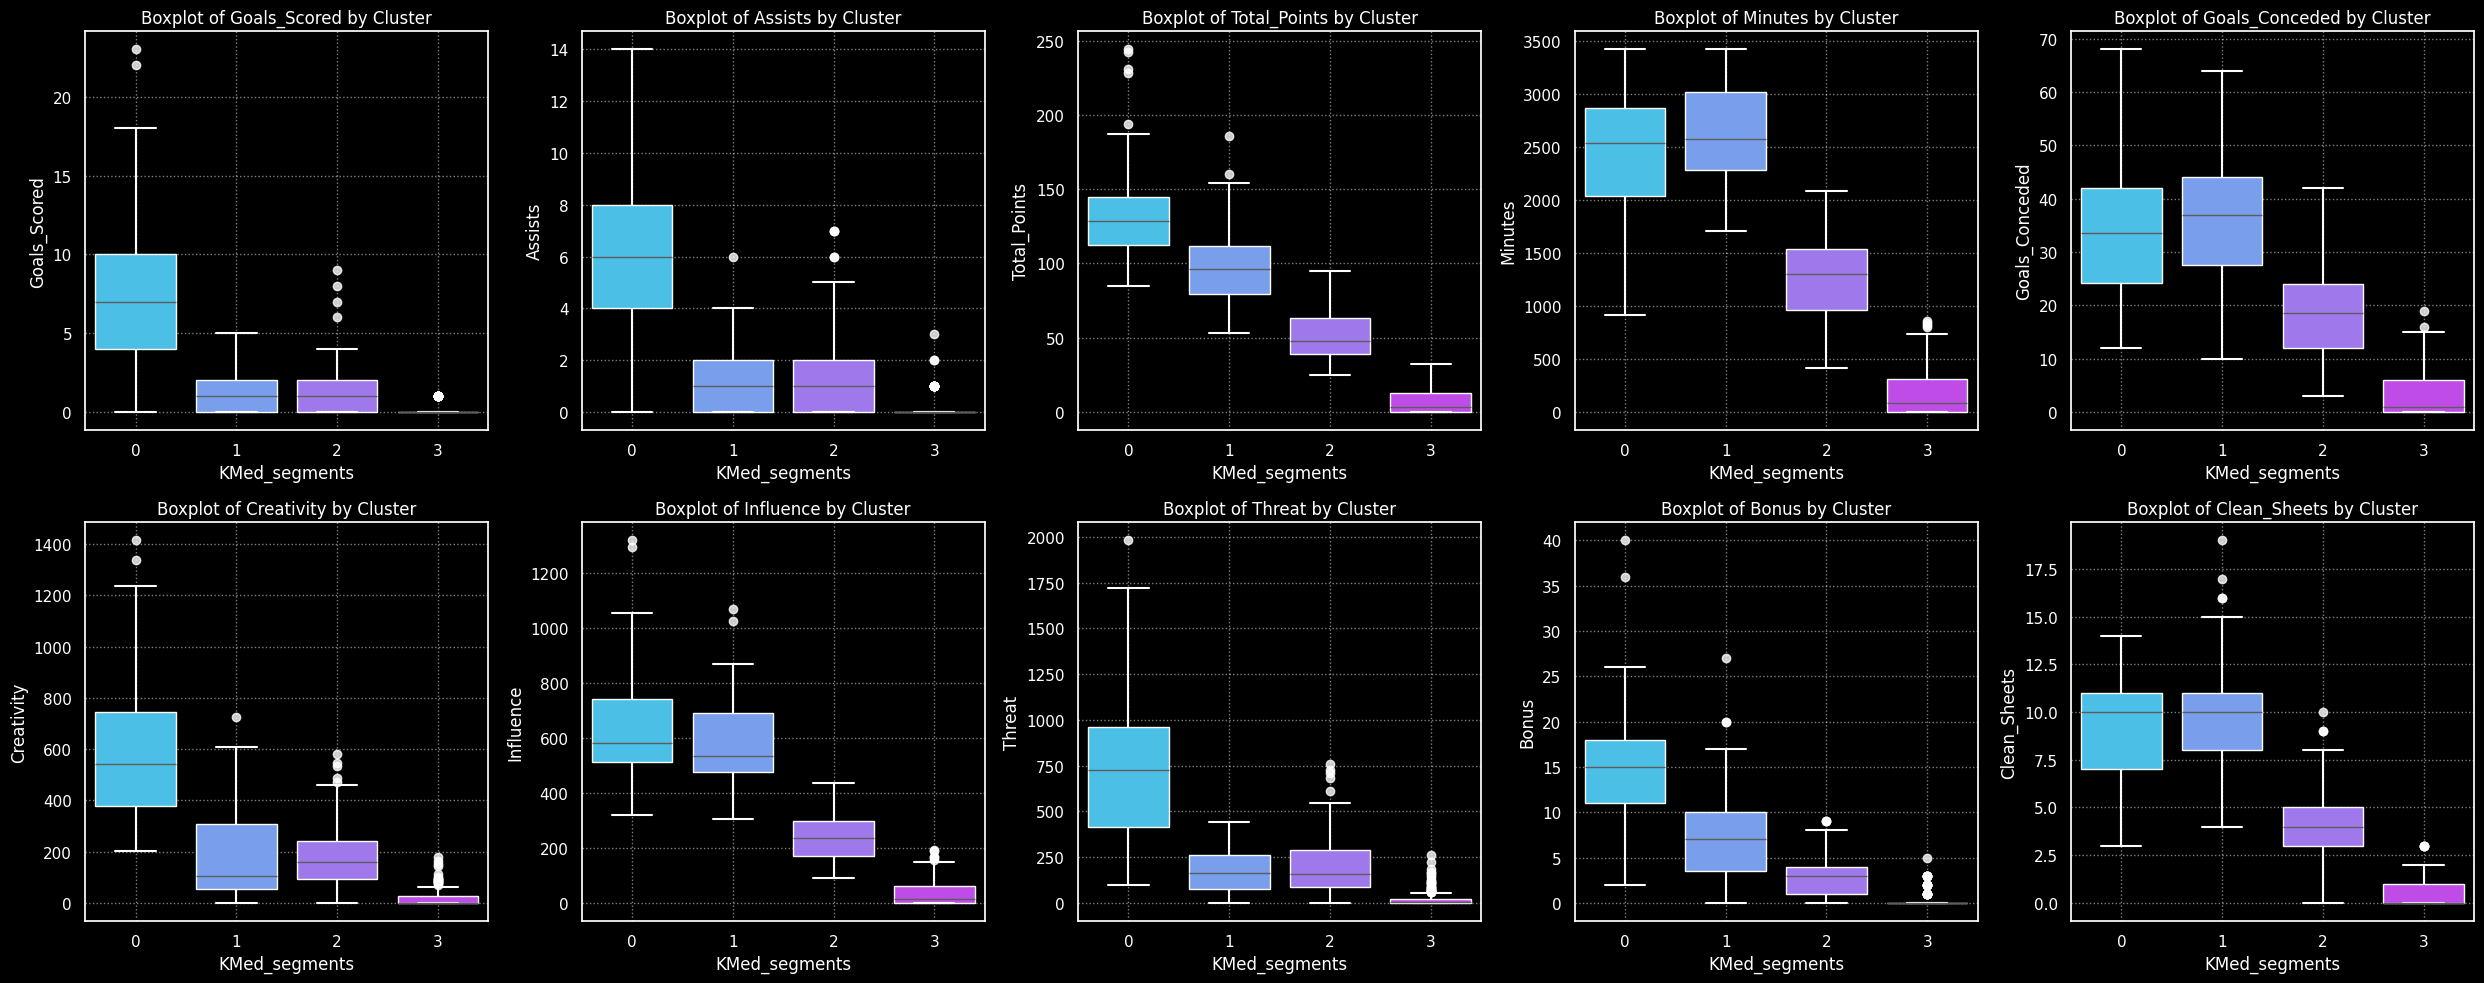

In [297]:

plt.style.use('dark_background')
# Create boxplot for each of the variables
# Create a clean grid of boxplots with white outliers and whiskers for the first 10 numerical columns
fig, axes = plt.subplots(2, 5, figsize=(25, 10))
axes = axes.flatten() # Flatten to easily iterate with a single loop

numeric_cols_list = df2.select_dtypes(include=np.number).columns.tolist()
# Exclude the segment label from the features to plot
features_to_plot = [col for col in numeric_cols_list if col != "KMed_segments"][:10]

for i, feature in enumerate(features_to_plot):
    sns.boxplot(
        data=df2,
        x="KMed_segments",
        y=feature,
        ax=axes[i],
        palette="cool",
        # Customizing colors: white outliers (flierprops) and white whiskers/caps
        flierprops={'markerfacecolor': '#ffffff', 'markeredgecolor': '#ffffff', 'marker': 'o', 'alpha': 0.8},
        boxprops={'edgecolor': '#ffffff'},
        whiskerprops={'color': '#ffffff', 'linewidth': 1.5},
        capprops={'color': '#ffffff', 'linewidth': 1.5}
    )
    axes[i].set_title(f"Boxplot of {feature} by Cluster", color='#ffffff')
    axes[i].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()


### **Characteristics of each cluster:** # Characteristics of each cluster:

* **Cluster 0 (High-Impact Attackers & Creative Playmakers):** Represented by archetypes like **Gylfi Sigurdsson**, this cluster captures elite midfielders and forwards. It displays the highest averages in **Goals Scored**, **Assists**, **Creativity**, **Threat**, and **Bonus** points, commanding top-tier valuation.
* **Cluster 1 (Durable Defensive Anchors & Goalkeepers):** Represented by archetypes like **Ben Godfrey**, this group features high-minute starters, goalkeepers, and defensive stalwarts. It dominates metrics like **Minutes**, **Clean Sheets**, and **Goals Conceded**, providing stable baseline returns.
* **Cluster 2 (Rotational Squad Players & Mid-Tier Regulars):** Represented by archetypes like **Alexis Mac Allister**, this cluster groups regular squad members and rotational starters with moderate, balanced outputs across minutes, points, and creation.
* **Cluster 3 (Low-Minute Enablers & Reserves):** Represented by archetypes like **Shkodran Mustafi**, this cluster consists of fringe players, long-term reserves, or low-exposure substitutes with metrics clustering near zero, serving as budget enablers.

---

# Comparison of cluster profiles from K-Means and K-Medoids:

* **Center Definition:** Standard K-Means defines cluster centers using mathematical means (artificial averages of the data points), whereas K-Medoids designates actual, real observations as cluster centers (the medoids, e.g., real players like Gylfi Sigurdsson or Ben Godfrey).
* **Robustness to Outliers:** K-Medoids is generally more robust to extreme performance outliers (like elite goalscorers) because it minimizes absolute distances using real data points, whereas K-Means uses squared Euclidean distances which can pull centroids toward extreme values.
* **Profile Interpretation:** While both algorithms successfully segment the player pool into 4 distinct tactical and performance tiers (Elite Attackers, Defensive Anchors, Rotational Starters, and Low-Minute Bench Enablers), K-Medoids makes business interpretation more intuitive by directly tying each cluster center to an actual player profile.
* **Shifting Cluster Assignments between K Means to K Medoids:** Because K-Means and K-Medoids use different mathematical rules (averages vs. real data points), several players—especially rotation options, mid-tier midfielders, and fringe defenders—are categorized into different clusters between the two models.
* **Which clustering method is better?** It is not necessarily a matter of "better" or "worse" accuracy, but rather a different perspective on group boundaries. However, K-Medoids often provides a more realistic and grounded grouping because every cluster center is an actual player, preventing extreme outliers from skewing the segment definitions.

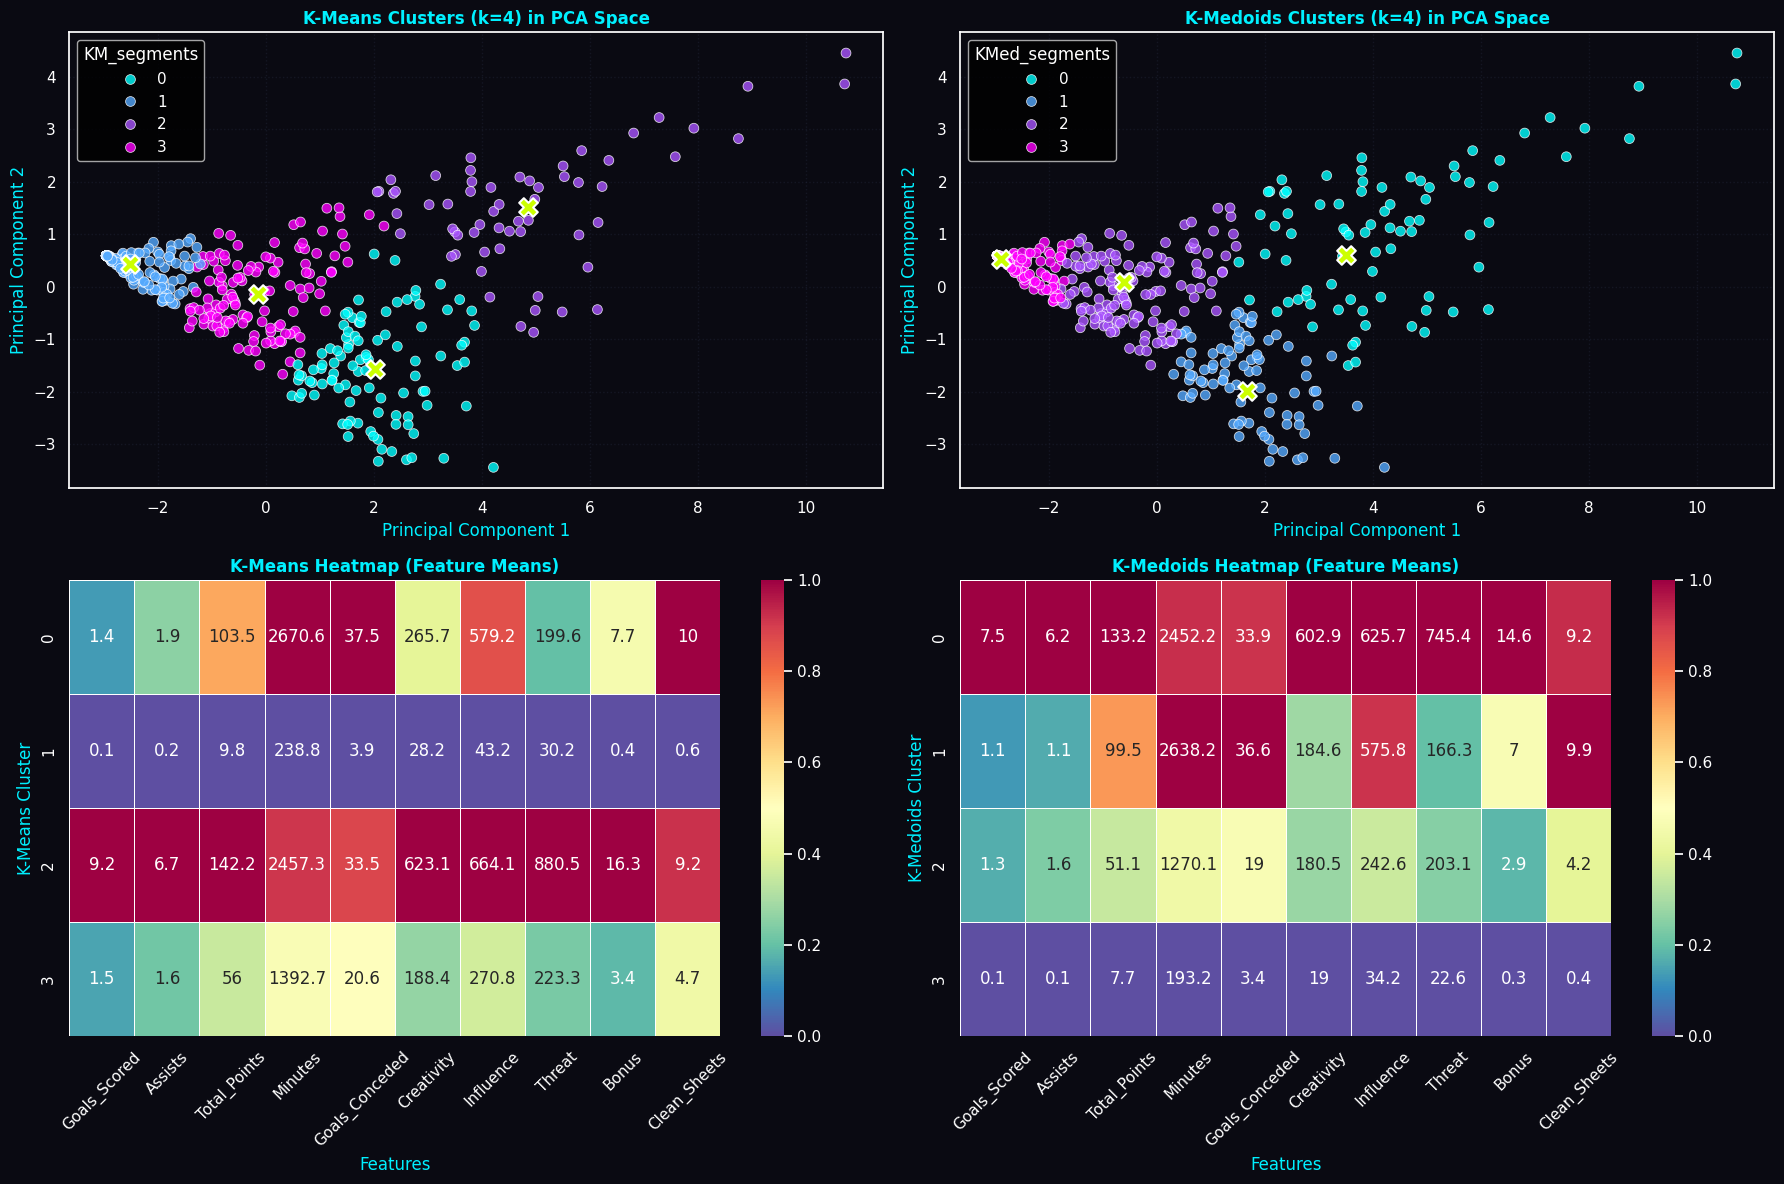

In [301]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Configurar estilo visual oscuro
plt.style.use('dark_background')
fig, axes = plt.subplots(2, 2, figsize=(18, 12), facecolor='#0a0a12')

# -------------------------------------------------------------
# 1. K-Means Clusters in PCA Space (Top Left)
# -------------------------------------------------------------
ax1 = axes[0, 0]
ax1.set_facecolor('#0a0a12')

plot_df = pd.DataFrame(pca_data[:, :2], columns=['PC1', 'PC2'])
plot_df['KM_segments'] = kmeans.labels_

sns.scatterplot(
    data=plot_df, x='PC1', y='PC2', hue='KM_segments',
    palette='cool', alpha=0.8, s=50, ax=ax1, legend='full'
)
centroids = kmeans.cluster_centers_[:, :2]
ax1.scatter(
    centroids[:, 0], centroids[:, 1], marker='X', s=180,
    color='#ccff00', edgecolors='#ffffff', linewidths=1.5, label='Centroids', zorder=5
)
ax1.set_title("K-Means Clusters (k=4) in PCA Space", color='#00f0ff', fontweight='bold')
ax1.set_xlabel("Principal Component 1", color='#00f0ff')
ax1.set_ylabel("Principal Component 2", color='#00f0ff')
ax1.grid(True, linestyle=':', alpha=0.5, color='#1f2335')

# -------------------------------------------------------------
# 2. K-Medoids Clusters in PCA Space (Top Right)
# -------------------------------------------------------------
ax2 = axes[0, 1]
ax2.set_facecolor('#0a0a12')

plot_kmed_df = pd.DataFrame(pca_data[:, :2], columns=['PC1', 'PC2'])
plot_kmed_df['KMed_segments'] = kmed.labels_

sns.scatterplot(
    data=plot_kmed_df, x='PC1', y='PC2', hue='KMed_segments',
    palette='cool', alpha=0.8, s=50, ax=ax2, legend='full'
)
kmed_centroids = kmed.cluster_centers_[:, :2]
ax2.scatter(
    kmed_centroids[:, 0], kmed_centroids[:, 1], marker='X', s=180,
    color='#ccff00', edgecolors='#ffffff', linewidths=1.5, label='Medoids', zorder=5
)
ax2.set_title("K-Medoids Clusters (k=4) in PCA Space", color='#00f0ff', fontweight='bold')
ax2.set_xlabel("Principal Component 1", color='#00f0ff')
ax2.set_ylabel("Principal Component 2", color='#00f0ff')
ax2.grid(True, linestyle=':', alpha=0.5, color='#1f2335')

# -------------------------------------------------------------
# 3. K-Means Characteristic Heatmap (Bottom Left)
# -------------------------------------------------------------
ax3 = axes[1, 0]
ax3.set_facecolor('#0a0a12')

profile_heatmap = df1.groupby('KM_segments')[numeric_columns].mean()
normalized_profile = (profile_heatmap - profile_heatmap.min()) / (profile_heatmap.max() - profile_heatmap.min())

sns.heatmap(
    normalized_profile, annot=profile_heatmap.round(1), fmt='g',
    cmap='Spectral_r', linewidths=0.5, cbar=True, ax=ax3
)
ax3.set_title("K-Means Heatmap (Feature Means)", color='#00f0ff', fontweight='bold')
ax3.set_xlabel("Features", color='#00f0ff')
ax3.set_ylabel("K-Means Cluster", color='#00f0ff')
ax3.tick_params(axis='x', rotation=45)

# -------------------------------------------------------------
# 4. K-Medoids Characteristic Heatmap (Bottom Right)
# -------------------------------------------------------------
ax4 = axes[1, 1]
ax4.set_facecolor('#0a0a12')

kmed_profile_heatmap = df2.groupby('KMed_segments')[numeric_columns].mean()
kmed_normalized_profile = (kmed_profile_heatmap - kmed_profile_heatmap.min()) / (kmed_profile_heatmap.max() - kmed_profile_heatmap.min())

sns.heatmap(
    kmed_normalized_profile, annot=kmed_profile_heatmap.round(1), fmt='g',
    cmap='Spectral_r', linewidths=0.5, cbar=True, ax=ax4
)
ax4.set_title("K-Medoids Heatmap (Feature Means)", color='#00f0ff', fontweight='bold')
ax4.set_xlabel("Features", color='#00f0ff')
ax4.set_ylabel("K-Medoids Cluster", color='#00f0ff')
ax4.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Revertir a estilo por defecto de seaborn
plt.style.use('default')
sns.set_theme(style='darkgrid')

# Comparative Story of the Four Clusters (K-Means vs. K-Medoids)

* **1. The Elite Offensive Core (Top Performers):**
  * *K-Means:* Grouped as **Cluster 2**, capturing elite goalscorers and creators (like Mohamed Salah, Bruno Fernandes, and Harry Kane) who drive maximum fantasy points and bonus metrics.
  * *K-Medoids:* Represented by **Cluster 0** (anchored by real player *Gylfi Sigurdsson* and high-impact attackers), capturing this exact same premium tier of top-tier playmakers and attacking powerhouses.

* **2. The Durable Defensive Anchors:**
  * *K-Means:* Grouped as **Cluster 0**, capturing high-minute starting goalkeepers and reliable defenders (like Emiliano Martínez and Rúben Dias) who accumulate clean sheets and maximum playing time.
  * *K-Medoids:* Represented by **Cluster 1** (anchored by real player *Ben Godfrey* and solid defensive regulars), preserving the core narrative of steady, high-minute defensive accumulation.

* **3. The Rotational & Mid-Tier Regulars (Mixture of Top/Middle):**
  * *K-Means:* Grouped as **Cluster 3**, representing regular squad members and mid-table starters with moderate, balanced outputs across minutes and points.
  * *K-Medoids:* Represented by **Cluster 2** (anchored by real player *Alexis Mac Allister*), capturing this exact same intermediate bridge tier of reliable squad contributors and rotation options.

* **4. The Low-Minute Enablers & Reserves (Underperforming / Budget Pool):**
  * *K-Means:* Grouped as **Cluster 1**, capturing the large baseline of low-minute fringe players, benchwarmers, and zero-minute reserves.
  * *K-Medoids:* Represented by **Cluster 3** (anchored by real player *Shkodran Mustafi*), perfectly matching the story of budget enablers whose metrics cluster near zero.

  Note on data visualization: In PCA space, K-Means builds rigid boundaries from synthetic means that can stretch toward outliers, while K-Medoids uses tighter, data-driven boundaries anchored to real players like Gylfi Sigurdsson. Similarly, K-Means heatmaps smooth out variance through centroid averaging, whereas K-Medoids preserves authentic performance signatures. Despite minor visual color and ID variations across scatter plots, the narrative remains identical: both methods uncover the exact same four core market tiers—an Elite Offensive Core, Durable Defensive Anchors, Rotational/Mid-Tier Regulars, and Low-Minute Budget Enablers.

##  **Hierarchical Clustering**

In [ ]:
hc_df = data_pca.copy()

In [ ]:
hc_df1 = hc_df.copy()

In [ ]:
# List of distance metrics
distance_metrics = ["euclidean", "chebyshev", "mahalanobis", "cityblock"]

# List of linkage methods
linkage_methods = ["single", "complete", "average", "weighted"]

high_cophenet_corr = 0
high_dm_lm = [0, 0]

for dm in distance_metrics:
    for lm in linkage_methods:
        Z = linkage(hc_df1, metric = dm, method = lm)
        c, coph_dists = cophenet(Z, pdist(hc_df))
        print(
            "Cophenetic correlation for {} distance and {} linkage is {}.".format(
                dm.capitalize(), lm, c
            )
        )
        if high_cophenet_corr < c:
            high_cophenet_corr = c
            high_dm_lm[0] = dm
            high_dm_lm[1] = lm

# Printing the combination of distance metric and linkage method with the highest cophenetic correlation
print('*'*100)
print(
    "Highest cophenetic correlation is {}, which is obtained with {} distance and {} linkage.".format(
        high_cophenet_corr, high_dm_lm[0].capitalize(), high_dm_lm[1]
    )
)

**Let's explore different linkage methods with Euclidean distance only.**

In [ ]:
# List of linkage methods
linkage_methods = ["single", "complete", "average", "centroid", "ward", "weighted"]

high_cophenet_corr = 0
high_dm_lm = [0, 0]

for lm in linkage_methods:
    Z = linkage(hc_df1, metric = "euclidean", method = lm)
    c, coph_dists = cophenet(Z, pdist(hc_df))
    print("Cophenetic correlation for {} linkage is {}.".format(lm, c))
    if high_cophenet_corr < c:
        high_cophenet_corr = c
        high_dm_lm[0] = "euclidean"
        high_dm_lm[1] = lm

# Printing the combination of distance metric and linkage method with the highest cophenetic correlation
print('*'*100)
print(
    "Highest cophenetic correlation is {}, which is obtained with {} linkage.".format(
        high_cophenet_corr, high_dm_lm[1]
    )
)

**Let's view the dendrograms for the different linkage methods with Euclidean distance only.**

In [ ]:
# List of linkage methods
linkage_methods = ["single", "complete", "average", "centroid", "ward", "weighted"]

# Lists to save results of cophenetic correlation calculation
compare_cols = ["Linkage", "Cophenetic Coefficient"]
compare = []

# To create a subplot image
fig, axs = plt.subplots(len(linkage_methods), 1, figsize = (15, 30))

# We will enumerate through the list of linkage methods above
# For each linkage method, we will plot the dendrogram and calculate the cophenetic correlation
for i, method in enumerate(linkage_methods):
    Z = linkage(hc_df1, metric = "euclidean", method = method)

    dendrogram(Z, ax = axs[i])
    axs[i].set_title(f"Dendrogram ({method.capitalize()} Linkage)")

    coph_corr, coph_dist = cophenet(Z, pdist(hc_df))
    axs[i].annotate(
        f"Cophenetic\nCorrelation\n{coph_corr:0.2f}",
        (0.80, 0.80),
        xycoords="axes fraction",
    )

    compare.append([method, coph_corr])

In [ ]:
# Create and print a dataframe to compare cophenetic correlations for different linkage methods
df_cc = pd.DataFrame(compare, columns = compare_cols)
df_cc = df_cc.sort_values(by = "Cophenetic Coefficient")
df_cc

In [ ]:
HCmodel = AgglomerativeClustering(n_clusters = ___ , metric = ___ , linkage = ___ )  # Complete the code to define the hierarchical clustering with average linkage
HCmodel.fit(hc_df)

In [ ]:
# Creating a copy of the original data
df3 = df.copy()

# Adding hierarchical cluster labels to the Heirarhical and original dataframes
hc_df["HC_segments_L1"] = _______________
df3["HC_segments_L1"] = _______________

### **Cluster Profiling**

In [ ]:
# Take the cluster-wise mean of all the variables. Hint: First group 'df3' by cluster labels column and then find mean

In [ ]:
# Create the "count_in_each_segment" column in hierarchical cluster profile

In [ ]:
# Highlight the maximum average value among all the clusters for each of the variables

In [ ]:
# Complete the code to print the players in each cluster. Hint: Use the HC_segments feature

**We see that most of the players have been grouped into one cluster, and there are two very sparse clusters. This clustering does not look good as the clusters do not have enough variability.**

**Let us try using Ward linkage as it has more distinct and separated clusters (as seen from it's dendrogram before). 4 appears to be a good number of clusters from the dendrogram for Ward linkage.**

In [ ]:
hc_df2 = data_pca.copy()

In [ ]:
HCmodel = AgglomerativeClustering(n_clusters = ___ , metric = ___ , linkage = ___ )  # Complete the code to define the hierarchical clustering with Ward Linkage
HCmodel.fit(hc_df2)

In [ ]:
# Creating a copy of the original data
df3 = df.copy()

# Adding hierarchical cluster labels to the Heirarhical and original dataframes
hc_df["HC_segments_L2"] = _______________
df3["HC_segments_L2"] = _______________

### **Cluster Profiling**

In [ ]:
# Take the cluster-wise mean of all the variables. Hint: First group 'df3' by cluster labels column and then find mean

In [ ]:
# Create the "count_in_each_segment" column in hierarchical cluster profile

In [ ]:
# Highlight the maximum average value among all the clusters for each of the variables

In [ ]:
# Complete the code to print the players in each cluster. Hint: Use the HC_segments feature

**Let's plot the boxplot**

In [ ]:
# Create boxplot for each of the variables

### **Characteristics of each cluster:___**

### **Comparison of cluster profiles from Hierarchical and previous algorithms:___________________**


## **GMM clustering**

In [ ]:
gmm_df = data_pca.copy()

In [ ]:
gmm = GaussianMixture(________, random_state = 1) # Initializing the Gaussian Mixture algorithm with n_components = 4

gmm.fit(_____) # Fit the Gaussian Mixture algorithm on the gmm_df

### **Cluster Profiling**

In [ ]:
# Creating a copy of the original data
df4 = df.copy()

# Adding gmm cluster labels to the GMM and original dataframes
gmm_df["GMM_segments"] = ____________
df4["GMM_segments"] = _______________

In [ ]:
# Take the cluster-wise mean of all the variables. Hint: First group 'df4' by cluster labels column and then find mean

In [ ]:
# Create the "count_in_each_segment" column in gmm cluster profile

In [ ]:
# Highlight the maximum average value among all the clusters for each of the variables

In [ ]:
# Complete the code to print the players in each cluster. Hint: Use the GMM_segments feature

**Let's plot the boxplot**

In [ ]:
# Create boxplot for each of the variables

### **Characteristics of each cluster:___**

### **Comparison of cluster profiles from GMM and previous algorithms:______________________**

## **DBSCAN**

DBSCAN is a very powerful algorithm for finding high-density clusters, but the problem is determining the best set of hyperparameters to use with it. It includes two hyperparameters, `eps`, and `min samples`.

Since it is an unsupervised algorithm, you have no control over it, unlike a supervised learning algorithm, which allows you to test your algorithm on a validation set. The approach we can follow is basically trying out a bunch of different combinations of values and finding the silhouette score for each of them.

### **What is the silhouette score?**

Silhouette score is one of the methods for evaluating the quality of clusters created using clustering algorithms such as K-Means. The silhouette score is a measure of how similar an object is to its cluster (cohesion) compared to other clusters (separation). Silhouette score has a range of [-1, 1].

* Silhouette coefficients near +1 indicate that the sample is far away from the neighboring clusters.
* Silhouette score near -1 indicates that those samples might have been assigned to the wrong cluster.

In [ ]:
dbscan_df = data_pca.copy()
dbscan_df1 = dbscan_df.copy()

In [ ]:
# Initializing lists
eps_value = [2,3]                       # Taking random eps value
min_sample_values = [6,20]              # Taking random min_sample value

# Creating a dictionary for each of the values in eps_value with min_sample_values
res = {eps_value[i]: min_sample_values for i in range(len(eps_value))}

In [ ]:
# Finding the silhouette_score for each of the combination
high_silhouette_avg = 0                                               # Assigning 0 to the high_silhouette_avg variable
high_i_j = [0, 0]                                                     # Assigning 0's to the high_i_j list
key = res.keys()                                                      # Assigning dictionary keys to a variable called key
for i in key:
    z = res[i]                                                        # Assigning dictionary values of each i to z
    for j in z:
        db = DBSCAN(eps = i, min_samples = j).fit(dbscan_df)          # Applying DBScan to each of the combinations in dictionary
        core_samples_mask = np.zeros_like(db.labels_, dtype = bool)
        core_samples_mask[db.core_sample_indices_] = True
        labels = db.labels_
        silhouette_avg = silhouette_score(dbscan_df, labels)           # Finding silhouette score
        print(
            "For eps value =" + str(i),
            "For min sample =" + str(j),
            "The average silhoutte_score is :",
            silhouette_avg,                                            # Printing the silhouette score for each of the combinations
        )
        if high_silhouette_avg < silhouette_avg:                       # If the silhouette score is greater than 0 or the previous score, it will get appended to the high_silhouette_avg list with its combination of i and j
            high_i_j[0] = i
            high_i_j[1] = j

In [ ]:
# Printing the highest silhouette score
print(
    "Highest_silhoutte_avg is {} for eps = {} and min sample = {}".format(
        high_silhouette_avg, high_i_j[0], high_i_j[1]
    )
)

In [ ]:
# Applying DBSCAN with the hyperparmeter values that we got

# Fit DBSCAN algorithm with the above hyperparameter values

In [ ]:
# Creating a copy of the original data
df5 = df.copy()

# Add DBSCAN cluster labels to dbscan data
dbscan_df1["db_segments"] = ________________

# Add DBSCAN cluster labels to original data
df5["db_segments"] =  ___________________

### **Cluster Profiling**

In [ ]:
# Take the cluster-wise mean of all the variables. Hint: First group 'df5' by cluster labels column and then find mean

In [ ]:
# Create the "count_in_each_segment" column in hierarchical cluster profile

In [ ]:
# Highlight the maximum average value among all the clusters for each of the variables

**Think about it:**

- Changing the eps and min sample values will result in different DBSCAN results? Can we try more value for eps and min_sample?

**Observations and Insights:**

### **Choosing the Best Algorithm**

- Since cluster profiles are the same for every algorithm except DBSCAN, it is difficult to choose the best algorithm. We can compute the silhouette score to choose the best algorithm among all the algorithms.

In [ ]:
kmeans = KMeans(n_clusters = 4, random_state = 1, n_init = 'auto')        # Initializing K-Means with number of clusters as 4 and random_state = 1

preds = kmeans.fit_predict((data_pca))                   # Fitting and predicting K-Means on data_pca

score = silhouette_score(data_pca, preds)                # Calculating the silhouette score

print(score)

In [ ]:
# Initialize K-Medoids with number of clusters as 4 and random_state = 1

# Fitting and predicting K-Medoids on data_pca

# Calculate the silhouette score

# Print the score

In [ ]:
# Initialize Agglomerative Clustering with distance as Euclidean, linkage as ward with clusters = 4

# Fitting and predicting HC algorithm on data_pca

# Calculate the silhouette score

# Print the score

In [ ]:
# Initialize Gaussian Mixture algorithm with number of clusters as 4 and random_state = 1

# Fitting and predicting Gaussian Mixture algorithm on data_pca

# Calculate the silhouette score

# Print the score

**Think about it:**

- Which is the best algorithm here among all the algorithms?

## **Conclusion:**__


## **Recommendations:**__